# 01 — Retail Data Preparation
Chạy các cell theo thứ tự trên Google Colab. Khi được yêu cầu, tải lên `retail_analytical_dataset.csv`.

**Mục tiêu:** kiểm tra dữ liệu ở cấp dòng sản phẩm trong đơn hàng, chuyển kiểu ngày, giữ nguyên dữ liệu thiếu theo kênh bán và tạo file dùng cho phân tích tiếp theo.

File gốc được giữ trong `raw`; dữ liệu xử lý nằm trong `df`. Notebook không tự xóa dòng hoặc điền giá trị thiếu. Dữ liệu năm 2021 kết thúc ngày 20/02 nên không so sánh trực tiếp với cả năm trước.


In [ ]:
import io
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


## 1. Tải CSV lên
Chọn đúng một file CSV đã export từ phần A của Query 2. Colab sẽ đọc dòng đầu làm header; `NULL` và ô trống được đọc thành giá trị thiếu.


In [ ]:
from google.colab import files

uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError('Hãy tải lên đúng một file CSV.')
filename = next(iter(uploaded))
raw = pd.read_csv(io.BytesIO(uploaded[filename]), encoding='utf-8-sig', na_values=['NULL'])
print(f'File: {filename} | Shape: {raw.shape}')
display(raw.head())


Saving retail_prepared_dataset.csv to retail_prepared_dataset.csv
File: retail_prepared_dataset.csv | Shape: (62884, 36)


,order_number,line_item,order_date,order_year,order_month,order_month_start,month_name,day_of_week,sales_channel,delivery_date,delivery_days,customer_key,gender,customer_city,customer_state,customer_country,customer_continent,birthday,store_key,store_country,store_state,square_meters,open_date,product_key,product_name,brand,color,subcategory,category,quantity,unit_price_usd,unit_cost_usd,revenue,total_cost,gross_profit,line_gross_margin
0,366000,1,2016-01-01,2016,1,2016-01-01,January,Friday,Physical Store,NaN,NaN,265598,Male,London,Ontario,Canada,North America,1971-03-23,10,Canada,Nunavut,"1,210.0000",2015-04-04,1304,Contoso Lens Adapter M450 White,Contoso,White,Cameras & Camcorders Accessories,Cameras and camcorders,1,68.0000,31.2700,68.0000,31.2700,36.7300,0.5401
1,366001,1,2016-01-01,2016,1,2016-01-01,January,Friday,Online,2016-01-13,12.0000,1269051,Male,Auberry,California,United States,North America,1995-11-20,0,Online,Online,NaN,2010-01-01,1048,A. Datum SLR Camera X136 Silver,A. Datum,Silver,Digital SLR Cameras,Cameras and camcorders,2,427.0000,141.4700,854.0000,282.9400,571.0600,0.6687
2,366001,2,2016-01-01,2016,1,2016-01-01,January,Friday,Online,2016-01-13,12.0000,1269051,Male,Auberry,California,United States,North America,1995-11-20,0,Online,Online,NaN,2010-01-01,2007,Fabrikam Microwave 1.5CuFt X1100 Black,Fabrikam,Black,Microwaves,Home Appliances,1,665.9400,220.6400,665.9400,220.6400,445.3000,0.6687
3,366002,1,2016-01-01,2016,1,2016-01-01,January,Friday,Online,2016-01-12,11.0000,266019,Female,Red Deer,Alberta,Canada,North America,1962-08-24,0,Online,Online,NaN,2010-01-01,1106,Contoso SLR Camera M146 Orange,Contoso,Orange,Digital SLR Cameras,Cameras and camcorders,7,322.0000,148.0800,"2,254.0000","1,036.5600","1,217.4400",0.5401
4,366002,2,2016-01-01,2016,1,2016-01-01,January,Friday,Online,2016-01-12,11.0000,266019,Female,Red Deer,Alberta,Canada,North America,1962-08-24,0,Online,Online,NaN,2010-01-01,373,Adventure Works Laptop8.9 E0890 White,Adventure Works,White,Laptops,Computers,1,326.0000,166.2000,326.0000,166.2000,159.8000,0.4902


## 2. Kiểm tra cấu trúc và kiểu dữ liệu

In [ ]:
expected_columns = [
    'order_number', 'line_item', 'order_date', 'order_year', 'order_month',
    'order_month_start', 'month_name', 'day_of_week', 'sales_channel',
    'delivery_date', 'delivery_days', 'customer_key', 'gender',
    'customer_city', 'customer_state', 'customer_country',
    'customer_continent', 'birthday', 'store_key', 'store_country',
    'store_state', 'square_meters', 'open_date', 'product_key',
    'product_name', 'brand', 'color', 'subcategory', 'category',
    'quantity', 'unit_price_usd', 'unit_cost_usd', 'revenue',
    'total_cost', 'gross_profit', 'line_gross_margin'
]
assert raw.columns.tolist() == expected_columns, 'Header khác cấu trúc dự kiến; kiểm tra lại file.'
assert len(raw) > 0, 'File không có dòng dữ liệu.'
print('Số dòng dự kiến của bản export hiện tại: 62,884')
print('Số dòng thực tế:', len(raw))
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum()}))


Số dòng dự kiến của bản export hiện tại: 62,884
Số dòng thực tế: 62884


,dtype,missing
order_number,int64,0
line_item,int64,0
order_date,object,0
order_year,int64,0
order_month,int64,0
order_month_start,object,0
month_name,object,0
day_of_week,object,0
sales_channel,object,0
delivery_date,object,49719


## 3. Chuyển kiểu ngày và số
Nếu gặp giá trị không chuyển được, notebook dừng để bạn kiểm tra thay vì âm thầm biến thành giá trị thiếu. Các khóa định danh dùng số nguyên có hỗ trợ giá trị thiếu; không dùng chúng như đại lượng để tính trung bình.


In [ ]:
df = raw.copy(deep=True)
date_columns = ['order_date', 'order_month_start', 'delivery_date', 'birthday', 'open_date']
for col in date_columns:
    df[col] = pd.to_datetime(df[col], format='%Y-%m-%d', errors='raise')

integer_columns = ['order_number', 'line_item', 'order_year', 'order_month',
                   'customer_key', 'store_key', 'product_key', 'quantity', 'delivery_days']
for col in integer_columns:
    df[col] = pd.to_numeric(df[col], errors='raise').astype('Int64')

numeric_columns = ['square_meters', 'unit_price_usd', 'unit_cost_usd',
                   'revenue', 'total_cost', 'gross_profit', 'line_gross_margin']
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='raise')

display(df.dtypes.astype(str).rename('dtype').to_frame())
print('Khoảng ngày đặt hàng:', df.order_date.min(), 'đến', df.order_date.max())


,dtype
order_number,Int64
line_item,Int64
order_date,datetime64[ns]
order_year,Int64
order_month,Int64
order_month_start,datetime64[ns]
month_name,object
day_of_week,object
sales_channel,object
delivery_date,datetime64[ns]


Khoảng ngày đặt hàng: 2016-01-01 00:00:00 đến 2021-02-20 00:00:00


## 4. Kiểm tra dữ liệu thiếu và dòng trùng
Trong bản CSV đã kiểm tra, cửa hàng vật lý thiếu thông tin giao hàng; kênh Online thiếu diện tích cửa hàng. Giữ các giá trị này là missing, không gán thành 0 và không dùng `dropna()` cho toàn bộ bảng.


In [ ]:
missing = df.isna().sum().rename('missing_count').to_frame()
missing['missing_pct'] = missing['missing_count'] / len(df) * 100
display(missing.query('missing_count > 0'))

channel_missing = df.groupby('sales_channel', dropna=False).agg(
    rows=('order_number', 'size'),
    missing_delivery_date=('delivery_date', lambda x: x.isna().sum()),
    missing_delivery_days=('delivery_days', lambda x: x.isna().sum()),
    missing_square_meters=('square_meters', lambda x: x.isna().sum())
)
display(channel_missing)

print('Dòng trùng hoàn toàn:', df.duplicated().sum())
print('Khóa order_number + line_item bị trùng:', df.duplicated(['order_number', 'line_item']).sum())


,missing_count,missing_pct
delivery_date,49719,79.0646
delivery_days,49719,79.0646
square_meters,13165,20.9354


,rows,missing_delivery_date,missing_delivery_days,missing_square_meters
sales_channel,,,,
Online,13165,0,0,13165
Physical Store,49719,49719,49719,0


Dòng trùng hoàn toàn: 0
Khóa order_number + line_item bị trùng: 0


## 5. Kiểm tra quy tắc và công thức
Các kiểm tra dưới đây xác nhận tính nhất quán **bên trong CSV**. Chúng chưa thay thế việc đối chiếu với kết quả SQL độc lập. Nếu có lỗi, notebook hiển thị dòng liên quan và dừng trước bước xuất file.


In [ ]:
critical = ['order_number', 'line_item', 'order_date', 'order_month_start',
            'order_year', 'order_month', 'customer_key', 'product_key', 'store_key',
            'quantity', 'unit_price_usd', 'unit_cost_usd', 'revenue', 'total_cost',
            'gross_profit', 'line_gross_margin', 'sales_channel']
checks = {
    'Missing ở cột thiết yếu': df[critical].isna().any(axis=1),
    'Khóa dòng trùng': df.duplicated(['order_number', 'line_item'], keep=False),
    'Số lượng không dương': df.quantity.le(0),
    'Đơn giá hoặc giá vốn âm': df.unit_price_usd.lt(0) | df.unit_cost_usd.lt(0),
    'Năm/tháng không khớp ngày': df.order_year.ne(df.order_date.dt.year) | df.order_month.ne(df.order_date.dt.month),
    'Ngày đầu tháng không khớp': df.order_month_start.ne(df.order_date.dt.to_period('M').dt.to_timestamp()),
    'Kênh bán không khớp store_key': df.sales_channel.ne(pd.Series(np.where(df.store_key.eq(0).fillna(False), 'Online', 'Physical Store'), index=df.index)),
    'Ngày giao trước ngày đặt': df.delivery_date.lt(df.order_date),
    'Ngày giao và số ngày giao thiếu không đồng bộ': df.delivery_date.isna().ne(df.delivery_days.isna()),
    'Số ngày giao không khớp': df.delivery_date.notna() & df.delivery_days.ne((df.delivery_date - df.order_date).dt.days),
}
for label, actual, expected in [
    ('Doanh thu không khớp', df.revenue, df.quantity * df.unit_price_usd),
    ('Giá vốn không khớp', df.total_cost, df.quantity * df.unit_cost_usd),
    ('Lợi nhuận không khớp', df.gross_profit, df.revenue - df.total_cost),
]:
    checks[label] = pd.Series(~np.isclose(actual.to_numpy(dtype=float, na_value=np.nan),
                                         expected.to_numpy(dtype=float, na_value=np.nan),
                                         atol=0.01, rtol=0), index=df.index)

margin_expected = df.gross_profit / df.revenue.replace(0, np.nan)
checks['Biên lợi nhuận không khớp'] = pd.Series(
    ~np.isclose(df.line_gross_margin, margin_expected, atol=1e-8, rtol=0, equal_nan=True), index=df.index)
check_summary = pd.Series({name: int(mask.fillna(True).sum()) for name, mask in checks.items()}, name='failed_rows')
display(check_summary.to_frame())
for name, mask in checks.items():
    if mask.fillna(True).any():
        print(name)
        display(df.loc[mask.fillna(True)].head(5))
assert check_summary.sum() == 0, 'Có kiểm tra chưa đạt. Xem các dòng phía trên trước khi tiếp tục.'


,failed_rows
Missing ở cột thiết yếu,0
Khóa dòng trùng,0
Số lượng không dương,0
Đơn giá hoặc giá vốn âm,0
Năm/tháng không khớp ngày,0
Ngày đầu tháng không khớp,0
Kênh bán không khớp store_key,0
Ngày giao trước ngày đặt,0
Ngày giao và số ngày giao thiếu không đồng bộ,0
Số ngày giao không khớp,0


## 6. Tổng KPI và đối chiếu SQL
Số đơn = số `order_number` duy nhất, không phải số dòng. Gross margin tổng = tổng gross profit / tổng revenue, không phải trung bình `line_gross_margin`.

Các khoản tiền sử dụng cột USD đã export. Chạy câu SQL ở cell văn bản kế tiếp trong SSMS trên cùng nguồn dữ liệu, rồi điền kết quả vào `sql_expected`. Để `None` nếu chưa có; notebook sẽ báo **chưa đối chiếu**, không tự đánh dấu khớp.


In [ ]:
kpis = {
    'rows': len(df),
    'orders': df.order_number.nunique(),
    'customers': df.customer_key.nunique(),
    'units_sold': int(df.quantity.sum()),
    'revenue': float(df.revenue.sum()),
    'total_cost': float(df.total_cost.sum()),
    'gross_profit': float(df.gross_profit.sum()),
}
display(pd.Series(kpis, name='CSV').to_frame())
print('Gross margin tổng:', f"{kpis['gross_profit'] / kpis['revenue']:.2%}" if kpis['revenue'] else 'Không xác định')

sql_expected = {key: None for key in kpis}
# Ví dụ: sql_expected['rows'] = 62884
# Điền các giá trị thực tế từ SQL rồi chạy lại cell này.
reconciliation = pd.DataFrame({'CSV': kpis, 'SQL': sql_expected})
reconciliation['difference'] = reconciliation['CSV'] - pd.to_numeric(reconciliation['SQL'], errors='coerce')
reconciliation['status'] = [
    'Chưa đối chiếu' if sql_expected[key] is None else
    ('Khớp' if abs(reconciliation.loc[key, 'difference']) <= (0.01 if key in ['revenue', 'total_cost', 'gross_profit'] else 0) else 'Lệch')
    for key in reconciliation.index
]
display(reconciliation)


,CSV
rows,"62,884.0000"
orders,"26,326.0000"
customers,"11,887.0000"
units_sold,"197,757.0000"
revenue,"55,755,479.5900"
total_cost,"23,092,791.2100"
gross_profit,"32,662,688.3800"


Gross margin tổng: 58.58%


,CSV,SQL,difference,status
rows,"62,884.0000",None,NaN,Chưa đối chiếu
orders,"26,326.0000",None,NaN,Chưa đối chiếu
customers,"11,887.0000",None,NaN,Chưa đối chiếu
units_sold,"197,757.0000",None,NaN,Chưa đối chiếu
revenue,"55,755,479.5900",None,NaN,Chưa đối chiếu
total_cost,"23,092,791.2100",None,NaN,Chưa đối chiếu
gross_profit,"32,662,688.3800",None,NaN,Chưa đối chiếu


Chạy riêng câu SQL này trong SSMS, không ghép kết quả vào CSV chi tiết:

```sql
SELECT
    COUNT_BIG(*) AS rows,
    COUNT(DISTINCT s.order_number) AS orders,
    COUNT(DISTINCT s.customer_key) AS customers,
    SUM(CAST(s.quantity AS BIGINT)) AS units_sold,
    SUM(s.quantity * p.unit_price_usd) AS revenue,
    SUM(s.quantity * p.unit_cost_usd) AS total_cost,
    SUM(s.quantity * (p.unit_price_usd - p.unit_cost_usd)) AS gross_profit
FROM retails.sales s
LEFT JOIN retails.products p ON s.product_key = p.product_key
LEFT JOIN retails.customers c ON s.customer_key = c.customer_key
LEFT JOIN retails.stores st ON s.store_key = st.store_key;
```


## 7. Xuất dữ liệu đã chuẩn bị
Sắp xếp theo ngày và khóa dòng. Xuất CSV không kèm index. CSV không giữ kiểu datetime: ở notebook tiếp theo, dùng `parse_dates=date_columns` khi đọc lại. File này sẵn sàng làm đầu vào bước phân tích; hoàn tất đối chiếu SQL trước khi chốt kết quả kinh doanh.


In [ ]:
prepared = df.sort_values(['order_date', 'order_number', 'line_item']).reset_index(drop=True)
assert prepared.shape == raw.shape, 'Số dòng/cột đã thay đổi ngoài dự kiến.'
output_file = 'retail_prepared_dataset.csv'
prepared.to_csv(output_file, index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
print('Đã xuất:', output_file, '| Shape:', prepared.shape)
display(prepared.head())
files.download(output_file)


Đã xuất: retail_prepared_dataset.csv | Shape: (62884, 36)


,order_number,line_item,order_date,order_year,order_month,order_month_start,month_name,day_of_week,sales_channel,delivery_date,delivery_days,customer_key,gender,customer_city,customer_state,customer_country,customer_continent,birthday,store_key,store_country,store_state,square_meters,open_date,product_key,product_name,brand,color,subcategory,category,quantity,unit_price_usd,unit_cost_usd,revenue,total_cost,gross_profit,line_gross_margin
0,366000,1,2016-01-01,2016,1,2016-01-01,January,Friday,Physical Store,NaT,<NA>,265598,Male,London,Ontario,Canada,North America,1971-03-23,10,Canada,Nunavut,"1,210.0000",2015-04-04,1304,Contoso Lens Adapter M450 White,Contoso,White,Cameras & Camcorders Accessories,Cameras and camcorders,1,68.0000,31.2700,68.0000,31.2700,36.7300,0.5401
1,366001,1,2016-01-01,2016,1,2016-01-01,January,Friday,Online,2016-01-13,12,1269051,Male,Auberry,California,United States,North America,1995-11-20,0,Online,Online,NaN,2010-01-01,1048,A. Datum SLR Camera X136 Silver,A. Datum,Silver,Digital SLR Cameras,Cameras and camcorders,2,427.0000,141.4700,854.0000,282.9400,571.0600,0.6687
2,366001,2,2016-01-01,2016,1,2016-01-01,January,Friday,Online,2016-01-13,12,1269051,Male,Auberry,California,United States,North America,1995-11-20,0,Online,Online,NaN,2010-01-01,2007,Fabrikam Microwave 1.5CuFt X1100 Black,Fabrikam,Black,Microwaves,Home Appliances,1,665.9400,220.6400,665.9400,220.6400,445.3000,0.6687
3,366002,1,2016-01-01,2016,1,2016-01-01,January,Friday,Online,2016-01-12,11,266019,Female,Red Deer,Alberta,Canada,North America,1962-08-24,0,Online,Online,NaN,2010-01-01,1106,Contoso SLR Camera M146 Orange,Contoso,Orange,Digital SLR Cameras,Cameras and camcorders,7,322.0000,148.0800,"2,254.0000","1,036.5600","1,217.4400",0.5401
4,366002,2,2016-01-01,2016,1,2016-01-01,January,Friday,Online,2016-01-12,11,266019,Female,Red Deer,Alberta,Canada,North America,1962-08-24,0,Online,Online,NaN,2010-01-01,373,Adventure Works Laptop8.9 E0890 White,Adventure Works,White,Laptops,Computers,1,326.0000,166.2000,326.0000,166.2000,159.8000,0.4902


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd

snapshot_date = df["order_date"].max() + pd.Timedelta(days=1)

print("Ngày tham chiếu RFM:", snapshot_date.date())

Ngày tham chiếu RFM: 2021-02-21


In [ ]:
required_columns = [
    "customer_key",
    "order_number",
    "order_date",
    "revenue"
]

assert not df[required_columns].isna().any().any(), (
    "Có dữ liệu thiếu trong các cột cần để tính RFM."
)

rfm = (
    df.groupby("customer_key", as_index=False)
    .agg(
        last_order_date=("order_date", "max"),
        frequency=("order_number", "nunique"),
        monetary=("revenue", "sum")
    )
)

rfm["recency"] = (
    snapshot_date - rfm["last_order_date"]
).dt.days

rfm = rfm[
    [
        "customer_key",
        "last_order_date",
        "recency",
        "frequency",
        "monetary"
    ]
]

# Kiểm tra số khách hàng và doanh thu sau khi tổng hợp
assert len(rfm) == df["customer_key"].nunique()

assert np.isclose(
    rfm["monetary"].sum(),
    df["revenue"].sum(),
    atol=0.01,
    rtol=0
)

print("Số khách hàng:", len(rfm))

display(rfm.head())
display(rfm[["recency", "frequency", "monetary"]].describe())

Số khách hàng: 11887


,customer_key,last_order_date,recency,frequency,monetary
0,301,2019-11-11,468,1,592.0000
1,325,2020-01-04,414,3,"5,787.6700"
2,554,2019-12-05,444,2,951.7100
3,1042,2018-03-06,1083,1,"1,124.9100"
4,1314,2017-12-19,1160,1,"2,539.8600"


,recency,frequency,monetary
count,"11,887.0000","11,887.0000","11,887.0000"
mean,615.1421,2.2147,"4,690.4584"
std,406.2028,1.3915,"5,197.6227"
min,1.0000,1.0000,1.9900
25%,367.0000,1.0000,"1,138.9150"
50%,509.0000,2.0000,"2,995.0000"
75%,796.0000,3.0000,"6,425.0650"
max,"1,878.0000",14.0000,"61,871.7000"


In [ ]:
def score_metric(series, higher_is_better=True):
    percentile = series.rank(
        method="average",
        pct=True,
        ascending=higher_is_better
    )

    return (
        np.ceil(percentile * 5)
        .clip(1, 5)
        .astype(int)
    )


rfm["r_score"] = score_metric(
    rfm["recency"],
    higher_is_better=False
)

rfm["f_score"] = score_metric(
    rfm["frequency"],
    higher_is_better=True
)

rfm["m_score"] = score_metric(
    rfm["monetary"],
    higher_is_better=True
)

# Mã mô tả ba điểm, ví dụ: "545"
rfm["rfm_code"] = (
    rfm["r_score"].astype(str)
    + rfm["f_score"].astype(str)
    + rfm["m_score"].astype(str)
)

# Tổng điểm dùng để tham khảo
rfm["rfm_total"] = rfm[
    ["r_score", "f_score", "m_score"]
].sum(axis=1)

display(rfm.head())

,customer_key,last_order_date,recency,frequency,monetary,r_score,f_score,m_score,rfm_code,rfm_total
0,301,2019-11-11,468,1,592.0000,3,1,1,311,5
1,325,2020-01-04,414,3,"5,787.6700",4,4,4,444,12
2,554,2019-12-05,444,2,951.7100,3,3,2,332,8
3,1042,2018-03-06,1083,1,"1,124.9100",1,1,2,112,4
4,1314,2017-12-19,1160,1,"2,539.8600",1,1,3,113,5


In [ ]:
score_distribution = pd.DataFrame({
    column: rfm[column].value_counts().sort_index()
    for column in ["r_score", "f_score", "m_score"]
})

score_distribution = (
    score_distribution
    .reindex(range(1, 6), fill_value=0)
    .fillna(0)
    .astype(int)
)

score_distribution.index.name = "score"

display(score_distribution)

,r_score,f_score,m_score
score,,,
1,2376,4615,2377
2,2383,0,2377
3,2376,3410,2378
4,2378,2003,2377
5,2374,1859,2378


In [ ]:
conditions = [
    # Mua gần đây, thường xuyên và chi tiêu cao
    (
        (rfm["r_score"] >= 4)
        & (rfm["f_score"] >= 4)
        & (rfm["m_score"] >= 4)
    ),

    # Mua thường xuyên và còn tương đối gần đây
    (
        (rfm["r_score"] >= 3)
        & (rfm["f_score"] >= 4)
    ),

    # Mua gần đây nhưng mới có một đơn trong dữ liệu
    (
        (rfm["r_score"] >= 4)
        & (rfm["frequency"] == 1)
    ),

    # Lâu chưa quay lại, từng mua nhiều hoặc chi tiêu cao
    (
        (rfm["r_score"] <= 2)
        & (
            (rfm["f_score"] >= 4)
            | (rfm["m_score"] >= 4)
        )
    ),

    # Lâu chưa mua, tần suất và chi tiêu thấp
    (
        (rfm["r_score"] <= 2)
        & (rfm["f_score"] <= 2)
        & (rfm["m_score"] <= 2)
    )
]

labels = [
    "Champions",
    "Loyal Customers",
    "Recent One-time Buyers",
    "At Risk",
    "Hibernating"
]

rfm["segment"] = np.select(
    conditions,
    labels,
    default="Others"
)

display(rfm["segment"].value_counts().rename("customers"))

,customers
segment,
Others,4134
Hibernating,1896
Champions,1780
At Risk,1622
Loyal Customers,1428
Recent One-time Buyers,1027


In [ ]:
segment_summary = (
    rfm.groupby("segment")
    .agg(
        customers=("customer_key", "size"),
        median_recency_days=("recency", "median"),
        avg_frequency=("frequency", "mean"),
        avg_monetary_usd=("monetary", "mean"),
        total_revenue_usd=("monetary", "sum")
    )
)

segment_summary["customer_share_pct"] = (
    segment_summary["customers"]
    / segment_summary["customers"].sum()
    * 100
)

total_revenue = segment_summary["total_revenue_usd"].sum()

segment_summary["revenue_share_pct"] = (
    segment_summary["total_revenue_usd"] / total_revenue * 100
    if total_revenue != 0
    else np.nan
)

segment_summary = segment_summary[
    [
        "customers",
        "customer_share_pct",
        "median_recency_days",
        "avg_frequency",
        "avg_monetary_usd",
        "total_revenue_usd",
        "revenue_share_pct"
    ]
].sort_values(
    "total_revenue_usd",
    ascending=False
)

display(segment_summary.round(2))

,customers,customer_share_pct,median_recency_days,avg_frequency,avg_monetary_usd,total_revenue_usd,revenue_share_pct
segment,,,,,,,
Champions,1780,14.9700,286.0000,4.2500,"10,536.5000","18,754,973.2700",33.6400
Others,4134,34.7800,508.0000,1.7100,"3,221.4500","13,317,469.3900",23.8900
At Risk,1622,13.6500,811.0000,2.2600,"7,616.7000","12,354,285.3200",22.1600
Loyal Customers,1428,12.0100,447.0000,3.5800,"5,505.4600","7,861,802.2100",14.1000
Recent One-time Buyers,1027,8.6400,353.0000,1.0000,"1,941.2500","1,993,668.7000",3.5800
Hibernating,1896,15.9500,"1,004.0000",1.0000,777.0500,"1,473,280.7000",2.6400


phân tích chu kỳ mua lại

In [ ]:
orders = (
    df.groupby(
        ["customer_key", "order_number"],
        as_index=False
    )
    .agg(
        order_date=("order_date", "min"),
        order_revenue=("revenue", "sum")
    )
    .sort_values(
        ["customer_key", "order_date", "order_number"]
    )
    .reset_index(drop=True)
)

orders["previous_order_date"] = (
    orders.groupby("customer_key")["order_date"].shift(1)
)

orders["days_between_orders"] = (
    orders["order_date"] - orders["previous_order_date"]
).dt.days

display(orders.head(10))

,customer_key,order_number,order_date,order_revenue,previous_order_date,days_between_orders
0,301,1776007,2019-11-11,592.0000,NaT,NaN
1,325,1109001,2018-01-13,"3,966.0000",NaT,NaN
2,325,1781006,2019-11-16,923.7000,2018-01-13,672.0000
3,325,1830002,2020-01-04,897.9700,2019-11-16,49.0000
4,554,1100024,2018-01-04,357.0000,NaT,NaN
5,554,1800017,2019-12-05,594.7100,2018-01-04,700.0000
6,1042,1161009,2018-03-06,"1,124.9100",NaT,NaN
7,1314,1084004,2017-12-19,"2,539.8600",NaT,NaN
8,1568,1826040,2019-12-31,249.9900,NaT,NaN
9,1568,1879087,2020-02-22,"2,835.3000",2019-12-31,53.0000


In [ ]:
purchase_gaps = orders.loc[
    orders["days_between_orders"].notna()
].copy()

assert purchase_gaps["days_between_orders"].ge(0).all()

print("Tổng số đơn hàng:", len(orders))

print(
    "Khách hàng có ít nhất hai đơn:",
    purchase_gaps["customer_key"].nunique()
)

print("Số khoảng cách quan sát được:", len(purchase_gaps))

print(
    "Số khoảng cách bằng 0 ngày:",
    purchase_gaps["days_between_orders"].eq(0).sum()
)

display(
    purchase_gaps["days_between_orders"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])
    .rename("days_between_orders")
    .to_frame()
)

Tổng số đơn hàng: 26326
Khách hàng có ít nhất hai đơn: 7272
Số khoảng cách quan sát được: 14439
Số khoảng cách bằng 0 ngày: 31


,days_between_orders
count,"14,439.0000"
mean,350.5046
std,317.1583
min,0.0000
25%,106.0000
50%,259.0000
75%,504.0000
90%,813.0000
95%,"1,014.1000"
max,"1,853.0000"


In [ ]:
customer_cycle = (
    purchase_gaps.groupby("customer_key", as_index=False)
    .agg(
        observed_gaps=("days_between_orders", "size"),
        median_gap_days=("days_between_orders", "median"),
        mean_gap_days=("days_between_orders", "mean")
    )
)

# Tạo bảng mới để giữ nguyên bảng RFM ban đầu
rfm_cycle = rfm.merge(
    customer_cycle,
    on="customer_key",
    how="left",
    validate="one_to_one"
)

rfm_cycle["observed_gaps"] = (
    rfm_cycle["observed_gaps"]
    .fillna(0)
    .astype(int)
)

display(
    rfm_cycle[
        [
            "customer_key",
            "frequency",
            "recency",
            "observed_gaps",
            "median_gap_days",
            "segment"
        ]
    ].head(10)
)

,customer_key,frequency,recency,observed_gaps,median_gap_days,segment
0,301,1,468,0,NaN,Others
1,325,3,414,2,360.5000,Champions
2,554,2,444,1,700.0000,Others
3,1042,1,1083,0,NaN,Hibernating
4,1314,1,1160,0,NaN,Others
5,1568,4,11,3,172.0000,Champions
6,1585,2,724,1,367.0000,At Risk
7,1626,2,365,1,436.0000,Others
8,1642,1,642,0,NaN,Hibernating
9,1863,2,197,1,150.0000,Others


In [ ]:
eligible = (
    rfm_cycle["observed_gaps"].ge(2)
    & rfm_cycle["median_gap_days"].gt(0)
)

rfm_cycle["recency_to_cycle_ratio"] = np.nan

rfm_cycle.loc[eligible, "recency_to_cycle_ratio"] = (
    rfm_cycle.loc[eligible, "recency"]
    / rfm_cycle.loc[eligible, "median_gap_days"]
)

print("Khách hàng đủ điều kiện so sánh:", eligible.sum())

display(
    rfm_cycle.loc[
        eligible,
        [
            "customer_key",
            "segment",
            "recency",
            "median_gap_days",
            "recency_to_cycle_ratio"
        ]
    ]
    .sort_values("recency_to_cycle_ratio", ascending=False)
    .head(10)
)

Khách hàng đủ điều kiện so sánh: 3862


,customer_key,segment,recency,median_gap_days,recency_to_cycle_ratio
10535,1886968,Champions,428,3.0000,142.6667
2578,506515,Champions,416,5.0000,83.2000
952,227646,At Risk,1093,14.0000,78.0714
2557,503788,At Risk,774,12.0000,64.5000
3860,760987,Loyal Customers,477,7.5000,63.6000
7994,1484343,Champions,368,7.0000,52.5714
3865,761495,At Risk,757,17.0000,44.5294
4452,871241,At Risk,1182,30.5000,38.7541
7553,1414215,At Risk,768,23.0000,33.3913
9492,1719990,Loyal Customers,486,15.0000,32.4000


In [ ]:
cycle_summary = (
    rfm_cycle.groupby("segment")
    .agg(
        customers=("customer_key", "size"),
        customers_with_observed_cycle=(
            "median_gap_days", "count"
        ),
        customers_eligible_for_ratio=(
            "recency_to_cycle_ratio", "count"
        ),
        median_recency_days=("recency", "median"),
        median_customer_gap_days=(
            "median_gap_days", "median"
        ),
        median_recency_to_cycle_ratio=(
            "recency_to_cycle_ratio", "median"
        )
    )
)

cycle_summary["ratio_coverage_pct"] = (
    cycle_summary["customers_eligible_for_ratio"]
    / cycle_summary["customers"]
    * 100
)

display(cycle_summary.round(2))

,customers,customers_with_observed_cycle,customers_eligible_for_ratio,median_recency_days,median_customer_gap_days,median_recency_to_cycle_ratio,ratio_coverage_pct
segment,,,,,,,
At Risk,1622,1149,654,811.0000,269.0000,3.2500,40.3200
Champions,1780,1780,1780,286.0000,254.0000,0.9600,100.0000
Hibernating,1896,0,0,"1,004.0000",NaN,NaN,0.0000
Loyal Customers,1428,1428,1428,447.0000,281.2500,1.4700,100.0000
Others,4134,2915,0,508.0000,440.0000,NaN,0.0000
Recent One-time Buyers,1027,0,0,353.0000,NaN,NaN,0.0000


So sánh tỷ trọng khách hàng và doanh thu

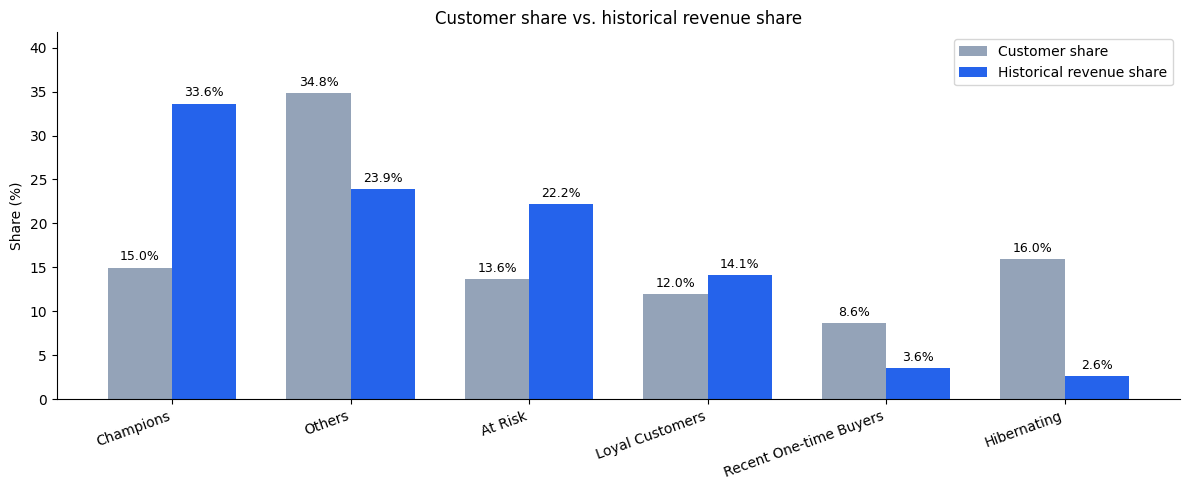

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plot_data = segment_summary.sort_values(
    "revenue_share_pct",
    ascending=False
)

x = np.arange(len(plot_data))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 5))

customer_bars = ax.bar(
    x - width / 2,
    plot_data["customer_share_pct"],
    width,
    label="Customer share",
    color="#94A3B8"
)

revenue_bars = ax.bar(
    x + width / 2,
    plot_data["revenue_share_pct"],
    width,
    label="Historical revenue share",
    color="#2563EB"
)

ax.bar_label(customer_bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.bar_label(revenue_bars, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(plot_data.index, rotation=20, ha="right")

ax.set_title("Customer share vs. historical revenue share")
ax.set_ylabel("Share (%)")
ax.set_ylim(
    0,
    plot_data[
        ["customer_share_pct", "revenue_share_pct"]
    ].to_numpy().max() * 1.2
)

ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

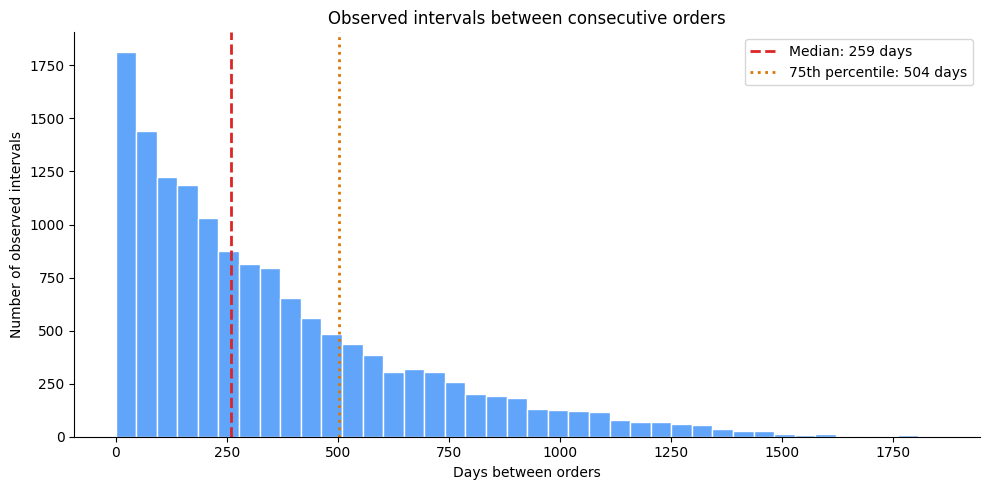

In [ ]:
gaps = purchase_gaps["days_between_orders"].dropna()

median_gap = gaps.median()
p75_gap = gaps.quantile(0.75)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    gaps,
    bins=40,
    color="#60A5FA",
    edgecolor="white"
)

ax.axvline(
    median_gap,
    color="#DC2626",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_gap:.0f} days"
)

ax.axvline(
    p75_gap,
    color="#D97706",
    linestyle=":",
    linewidth=2,
    label=f"75th percentile: {p75_gap:.0f} days"
)

ax.set_title("Observed intervals between consecutive orders")
ax.set_xlabel("Days between orders")
ax.set_ylabel("Number of observed intervals")

ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

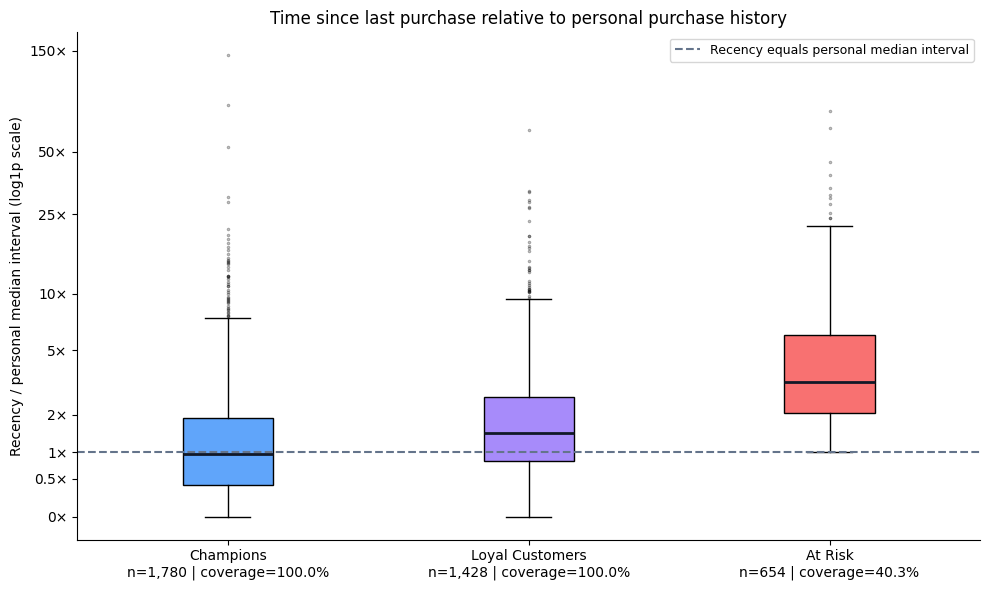

In [ ]:
segment_order = [
    "Champions",
    "Loyal Customers",
    "At Risk"
]

ratio_data = [
    rfm_cycle.loc[
        rfm_cycle["segment"].eq(segment),
        "recency_to_cycle_ratio"
    ].dropna()
    for segment in segment_order
]

labels = []

for segment, values in zip(segment_order, ratio_data):
    total_customers = rfm_cycle["segment"].eq(segment).sum()
    coverage = len(values) / total_customers * 100

    labels.append(
        f"{segment}\n"
        f"n={len(values):,} | coverage={coverage:.1f}%"
    )

fig, ax = plt.subplots(figsize=(10, 6))

boxes = ax.boxplot(
    [np.log1p(values.to_numpy()) for values in ratio_data],
    patch_artist=True,
    showfliers=True,
    flierprops={
        "marker": ".",
        "markersize": 3,
        "alpha": 0.35
    },
    medianprops={
        "color": "#111827",
        "linewidth": 2
    }
)

for patch, color in zip(
    boxes["boxes"],
    ["#60A5FA", "#A78BFA", "#F87171"]
):
    patch.set_facecolor(color)

# Hiển thị nhãn theo tỷ lệ gốc
ratio_ticks = np.array([0, 0.5, 1, 2, 5, 10, 25, 50, 150])

ax.set_yticks(np.log1p(ratio_ticks))
ax.set_yticklabels([f"{value:g}×" for value in ratio_ticks])

ax.axhline(
    np.log1p(1),
    color="#64748B",
    linestyle="--",
    label="Recency equals personal median interval"
)

ax.set_xticks(range(1, len(segment_order) + 1))
ax.set_xticklabels(labels)

ax.set_title("Time since last purchase relative to personal purchase history")
ax.set_ylabel("Recency / personal median interval (log1p scale)")

ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### RFM interpretation and business implications

Champions and At Risk customers together represent 28.62% of customers and contribute 55.80% of historical revenue. This concentration supports prioritizing these groups for further customer-level investigation.

Observed purchase intervals vary substantially, with a median of 259 days and a 75th percentile of 504 days. A short, universal inactivity threshold may therefore misrepresent purchasing behavior.

Among customers eligible for personal-cycle comparisons, the median recency-to-cycle ratio is 0.96 for Champions, 1.47 for Loyal Customers, and 3.25 for At Risk. The At Risk result covers only 40.32% of that segment.

Potential actions include reviewing high-value Champions with unusually long absences and testing reactivation campaigns for eligible At Risk customers. Campaign effectiveness should be evaluated against a control group rather than assumed from historical spending.

These findings describe behavior as of 21 February 2021. RFM segments and purchase-cycle ratios are exploratory indicators, not confirmed churn predictions.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

forecast_source = df[
    ["order_date", "quantity"]
].copy()

assert forecast_source.notna().all().all(), (
    "Có dữ liệu thiếu ở order_date hoặc quantity."
)

forecast_source["month"] = (
    forecast_source["order_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_demand = (
    forecast_source.groupby("month")
    .agg(units_sold=("quantity", "sum"))
    .sort_index()
)

monthly_demand["units_sold"] = (
    monthly_demand["units_sold"].astype(float)
)

assert np.isclose(
    monthly_demand["units_sold"].sum(),
    df["quantity"].sum()
)

print("Số tháng có dữ liệu:", len(monthly_demand))
display(monthly_demand.head())
display(monthly_demand.tail())

Số tháng có dữ liệu: 62


,units_sold
month,
2016-01-01,"2,116.0000"
2016-02-01,"2,676.0000"
2016-03-01,895.0000
2016-04-01,326.0000
2016-05-01,"1,646.0000"


,units_sold
month,
2020-10-01,"1,042.0000"
2020-11-01,"1,044.0000"
2020-12-01,"2,411.0000"
2021-01-01,"1,848.0000"
2021-02-01,"1,949.0000"


In [ ]:
all_months = pd.date_range(
    start=monthly_demand.index.min(),
    end=monthly_demand.index.max(),
    freq="MS"
)

missing_months = all_months.difference(
    monthly_demand.index
)

print(
    "Các tháng không có dữ liệu:",
    missing_months.strftime("%Y-%m").tolist()
)

assert len(missing_months) == 0, (
    "Có tháng thiếu dữ liệu. Cần xác minh trước khi tiếp tục."
)

# Mốc kết thúc dữ liệu đã biết của dataset
data_cutoff = pd.Timestamp("2021-02-20")
last_month_start = data_cutoff.to_period("M").to_timestamp()

assert forecast_source["order_date"].max() == data_cutoff

monthly_complete = (
    monthly_demand.loc[
        monthly_demand.index < last_month_start
    ]
    .copy()
    .asfreq("MS")
)

print("Loại khỏi mô hình: tháng 2021-02 chưa đầy đủ")
print("Số tháng giữ lại:", len(monthly_complete))
print(
    "Khoảng thời gian:",
    monthly_complete.index.min().strftime("%Y-%m"),
    "đến",
    monthly_complete.index.max().strftime("%Y-%m")
)

display(monthly_complete.tail())

Các tháng không có dữ liệu: []
Loại khỏi mô hình: tháng 2021-02 chưa đầy đủ
Số tháng giữ lại: 61
Khoảng thời gian: 2016-01 đến 2021-01


,units_sold
month,
2020-09-01,"1,328.0000"
2020-10-01,"1,042.0000"
2020-11-01,"1,044.0000"
2020-12-01,"2,411.0000"
2021-01-01,"1,848.0000"


In [ ]:
test_months = 12

assert len(monthly_complete) >= 36, (
    "Cần đủ dữ liệu để có ít nhất 24 tháng train và 12 tháng test."
)

train = monthly_complete.iloc[:-test_months].copy()
test = monthly_complete.iloc[-test_months:].copy()

assert train.index.max() < test.index.min()

split_summary = pd.DataFrame({
    "dataset": ["Train", "Test"],
    "start": [
        train.index.min().strftime("%Y-%m"),
        test.index.min().strftime("%Y-%m")
    ],
    "end": [
        train.index.max().strftime("%Y-%m"),
        test.index.max().strftime("%Y-%m")
    ],
    "months": [len(train), len(test)]
})

display(split_summary)

,dataset,start,end,months
0,Train,2016-01,2020-01,49
1,Test,2020-02,2021-01,12


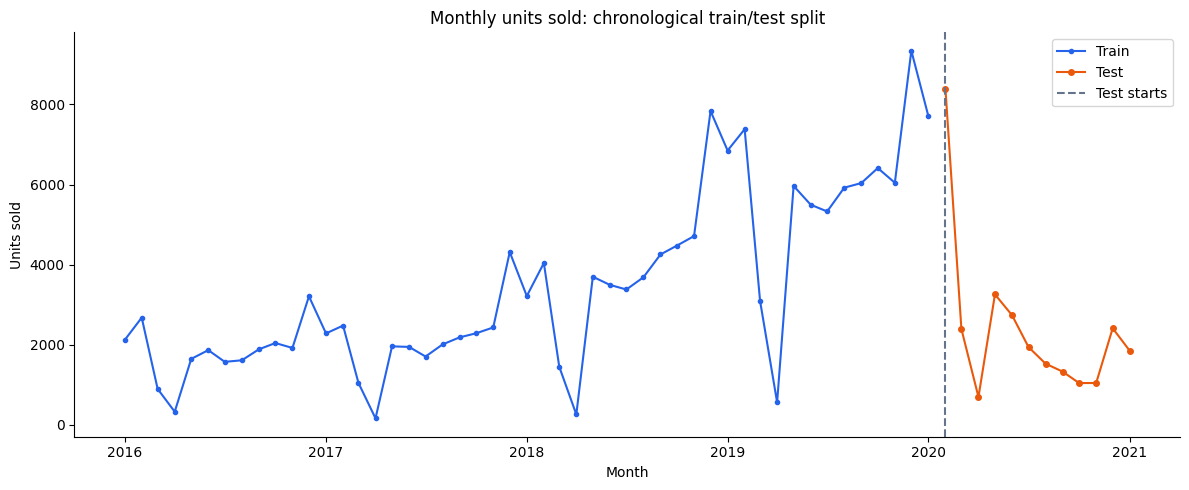

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    train.index,
    train["units_sold"],
    label="Train",
    color="#2563EB",
    marker="o",
    markersize=3
)

ax.plot(
    test.index,
    test["units_sold"],
    label="Test",
    color="#EA580C",
    marker="o",
    markersize=4
)

ax.axvline(
    test.index.min(),
    color="#64748B",
    linestyle="--",
    label="Test starts"
)

ax.set_title("Monthly units sold: chronological train/test split")
ax.set_xlabel("Month")
ax.set_ylabel("Units sold")

ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

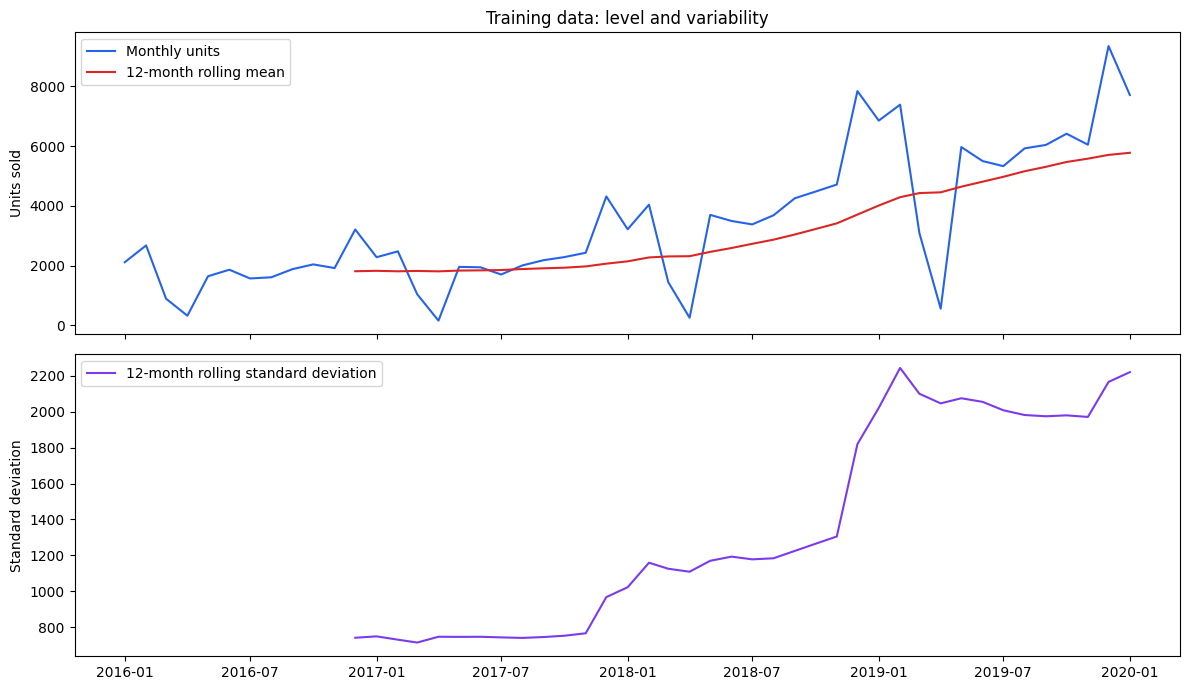

In [ ]:
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

y_train = train["units_sold"].astype(float).asfreq("MS")

assert y_train.notna().all()
assert len(y_train) >= 24

rolling_mean = y_train.rolling(window=12).mean()
rolling_std = y_train.rolling(window=12).std()

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True
)

axes[0].plot(y_train, label="Monthly units", color="#2563EB")
axes[0].plot(
    rolling_mean,
    label="12-month rolling mean",
    color="#DC2626"
)

axes[0].set_title("Training data: level and variability")
axes[0].set_ylabel("Units sold")
axes[0].legend()

axes[1].plot(
    rolling_std,
    label="12-month rolling standard deviation",
    color="#7C3AED"
)

axes[1].set_ylabel("Standard deviation")
axes[1].legend()

plt.tight_layout()
plt.show()

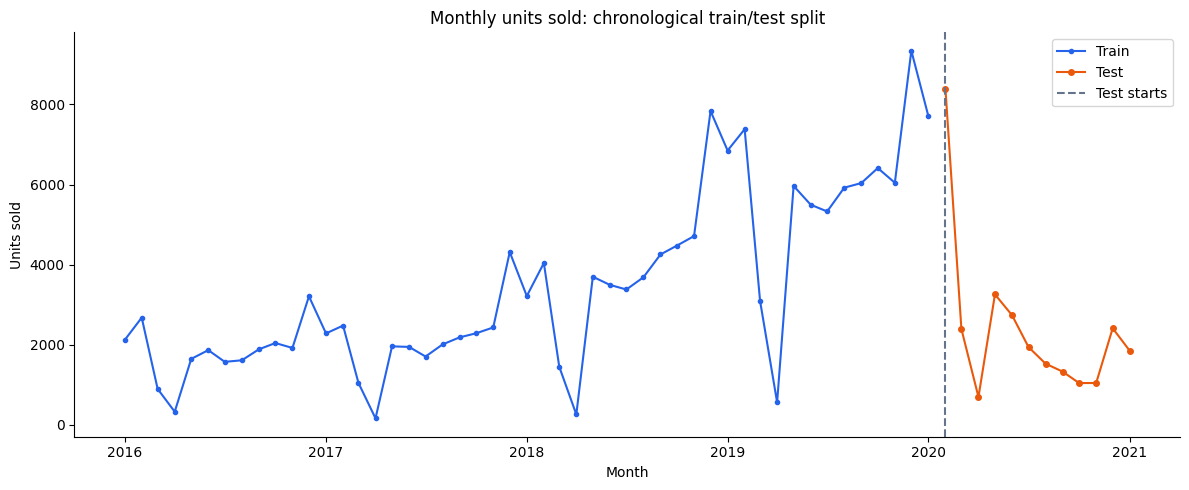

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    train.index,
    train["units_sold"],
    label="Train",
    color="#2563EB",
    marker="o",
    markersize=3
)

ax.plot(
    test.index,
    test["units_sold"],
    label="Test",
    color="#EA580C",
    marker="o",
    markersize=4
)

ax.axvline(
    test.index.min(),
    color="#64748B",
    linestyle="--",
    label="Test starts"
)

ax.set_title("Monthly units sold: chronological train/test split")
ax.set_xlabel("Month")
ax.set_ylabel("Units sold")

ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

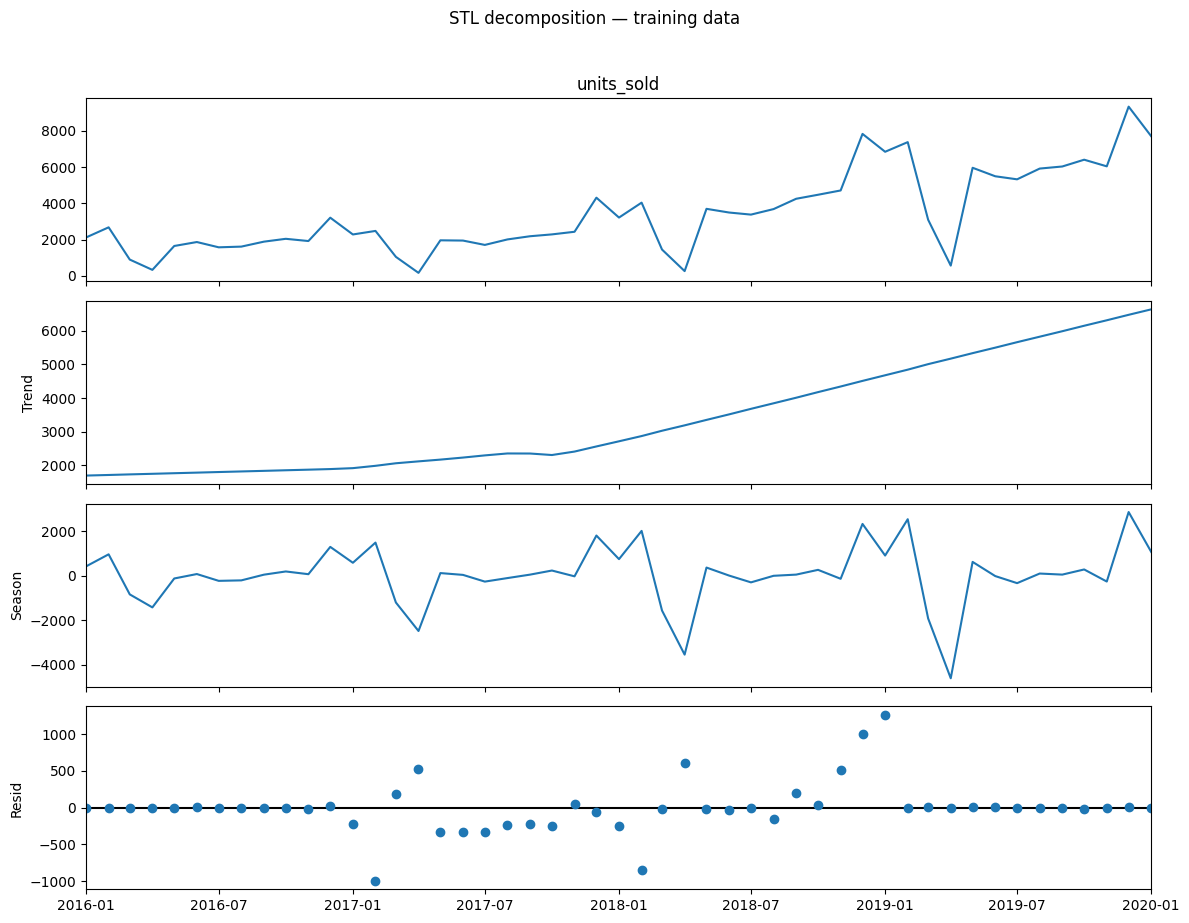

In [ ]:
stl_result = STL(
    y_train,
    period=12,
    robust=True
).fit()

fig = stl_result.plot()
fig.set_size_inches(12, 9)
fig.suptitle(
    "STL decomposition — training data",
    y=1.02
)

plt.tight_layout()
plt.show()

In [ ]:
def stationarity_tests(series, label):
    values = series.dropna().astype(float)

    adf_result = adfuller(
        values,
        regression="c",
        autolag="AIC",
        result_object=False
    )

    kpss_result = kpss(
        values,
        regression="c",
        nlags="auto",
        result_object=False
    )

    return {
        "series": label,
        "n": len(values),
        "ADF_stat": adf_result[0],
        "ADF_p": adf_result[1],
        "ADF_lags": adf_result[2],
        "KPSS_stat": kpss_result[0],
        "KPSS_p": kpss_result[1],
        "KPSS_lags": kpss_result[2]
    }


original_tests = pd.DataFrame([
    stationarity_tests(y_train, "Original")
]).set_index("series")

display(original_tests.round(4))

/tmp/ipykernel_589/735950707.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(


,n,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,KPSS_lags
series,,,,,,,
Original,49,3.0567,1.0000,11,0.9229,0.0100,4


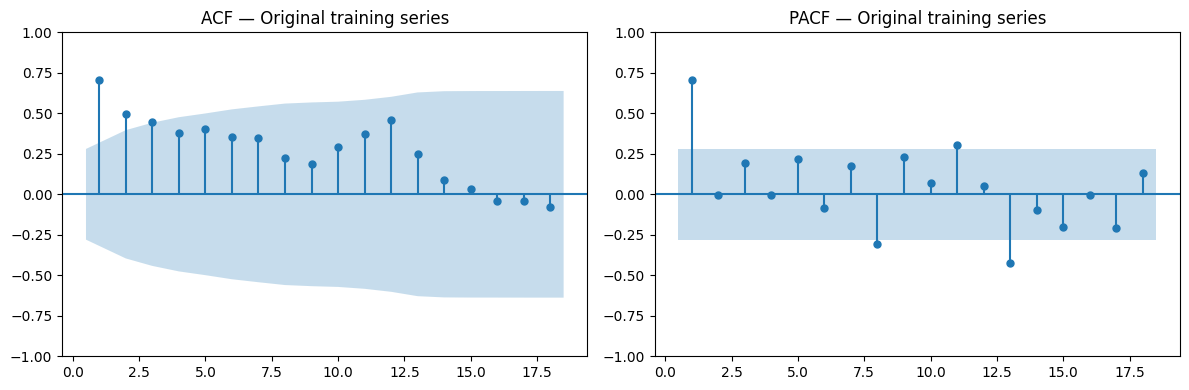

In [ ]:
def plot_correlation(series, title):
    values = series.dropna()

    # PACF yêu cầu số lag nhỏ hơn một nửa số quan sát
    max_lags = min(18, len(values) // 2 - 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    plot_acf(
        values,
        lags=max_lags,
        zero=False,
        ax=axes[0]
    )

    plot_pacf(
        values,
        lags=max_lags,
        zero=False,
        method="ywm",
        ax=axes[1]
    )

    axes[0].set_title(f"ACF — {title}")
    axes[1].set_title(f"PACF — {title}")

    plt.tight_layout()
    plt.show()


plot_correlation(y_train, "Original training series")

In [ ]:
candidate_series = {
    "Original": y_train,
    "First difference": y_train.diff(),
    "Seasonal difference (12)": y_train.diff(12),
    "First + seasonal difference": y_train.diff(12).diff()
}

stationarity_comparison = pd.DataFrame([
    stationarity_tests(series, name)
    for name, series in candidate_series.items()
]).set_index("series")

display(stationarity_comparison.round(4))

/tmp/ipykernel_589/735950707.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_589/735950707.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(


,n,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,KPSS_lags
series,,,,,,,
Original,49,3.0567,1.0000,11,0.9229,0.0100,4
First difference,48,-6.2007,0.0000,10,0.4007,0.0768,23
Seasonal difference (12),37,-2.2130,0.2016,0,0.6627,0.0169,3
First + seasonal difference,36,-6.5906,0.0000,0,0.2251,0.1000,8


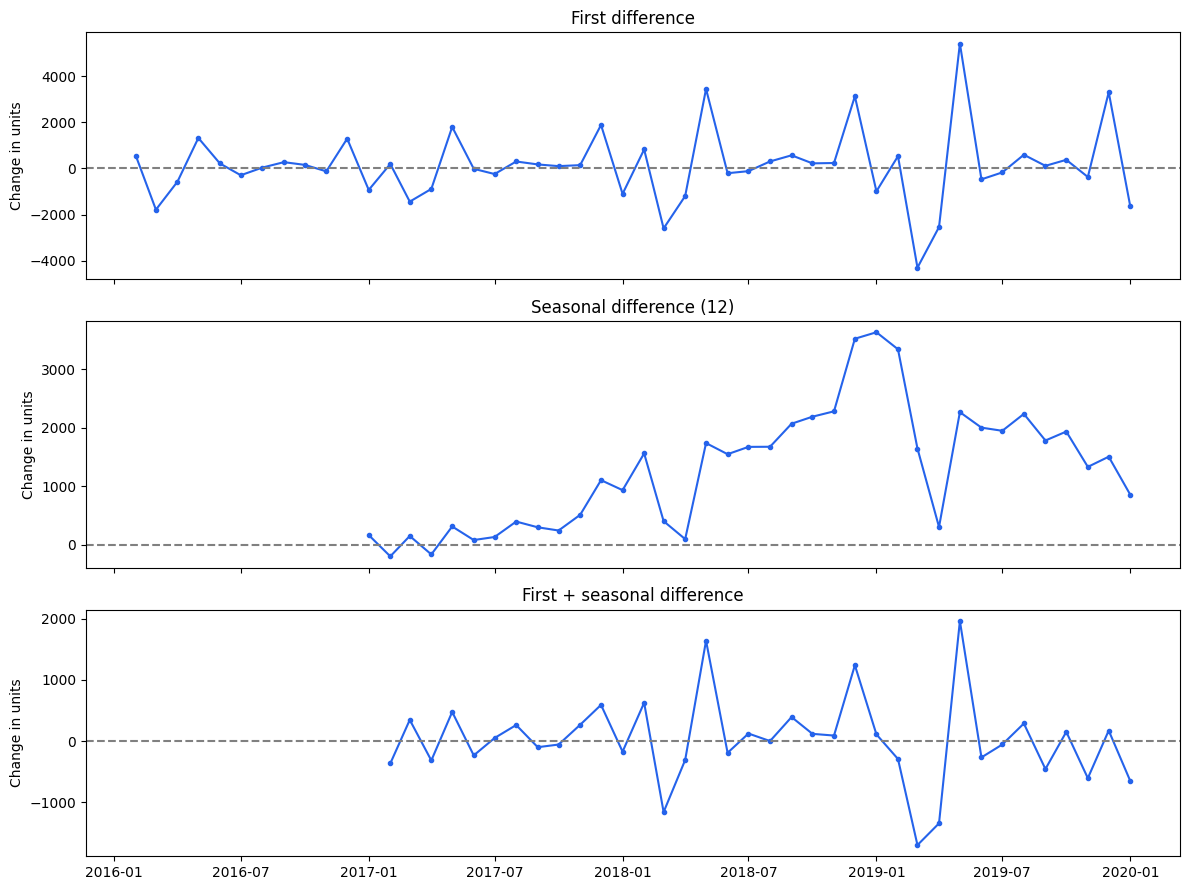

In [ ]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 9),
    sharex=True
)

for ax, (name, series) in zip(
    axes,
    list(candidate_series.items())[1:]
):
    ax.plot(
        series.dropna(),
        color="#2563EB",
        marker="o",
        markersize=3
    )

    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(name)
    ax.set_ylabel("Change in units")

plt.tight_layout()
plt.show()

In [ ]:
sensitivity_rows = []

for name in ["Original", "First difference"]:
    values = candidate_series[name].dropna().astype(float)

    for lag in [0, 1, 3, 6, 12]:
        adf_result = adfuller(
            values,
            regression="c",
            maxlag=lag,
            autolag=None,
            result_object=False
        )

        kpss_result = kpss(
            values,
            regression="c",
            nlags=lag,
            result_object=False
        )

        sensitivity_rows.append({
            "series": name,
            "lag": lag,
            "ADF_p": adf_result[1],
            "KPSS_p": kpss_result[1]
        })

sensitivity_table = pd.DataFrame(sensitivity_rows)

display(
    sensitivity_table.style.format({
        "ADF_p": "{:.3g}",
        "KPSS_p": "{:.3g}"
    })
)

/tmp/ipykernel_589/4003549339.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_589/4003549339.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_589/4003549339.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_589/4003549339.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_589/4003549339.py:15: InterpolationWarning: The test statistic is outside of the rang

,series,lag,ADF_p,KPSS_p
0,Original,0,0.187,0.01
1,Original,1,0.465,0.01
2,Original,3,0.798,0.01
3,Original,6,0.973,0.0108
4,Original,12,0.194,0.0452
5,First difference,0,2.67e-13,0.1
6,First difference,1,8.24e-10,0.1
7,First difference,3,8.39e-07,0.1
8,First difference,6,0.0846,0.1
9,First difference,12,0.553,0.1


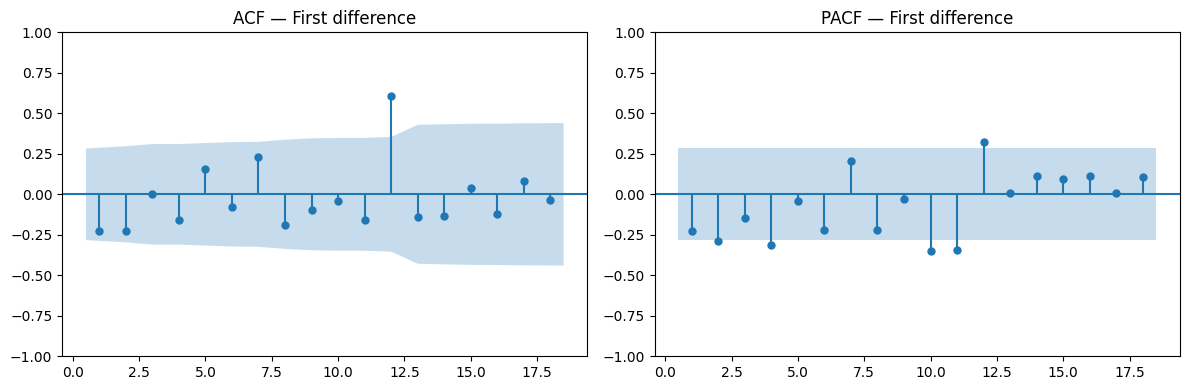

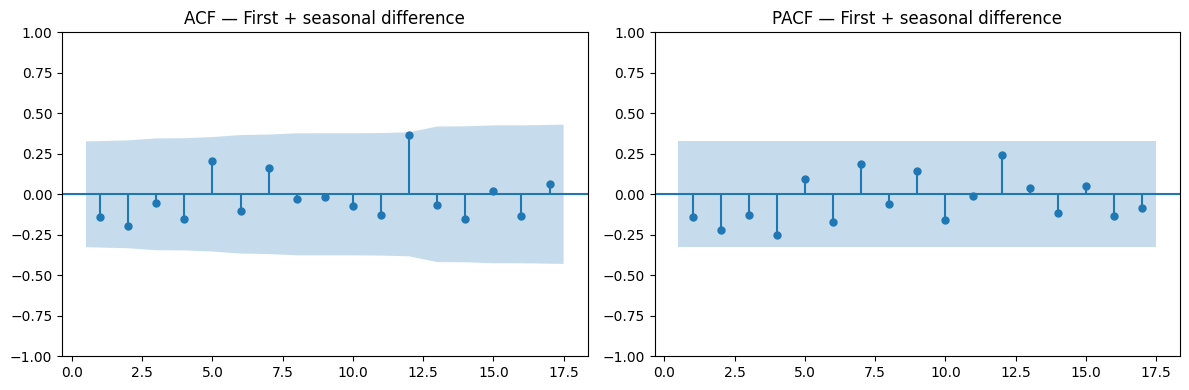

In [ ]:
plot_correlation(
    y_train.diff(),
    "First difference"
)

plot_correlation(
    y_train.diff(12).diff(),
    "First + seasonal difference"
)

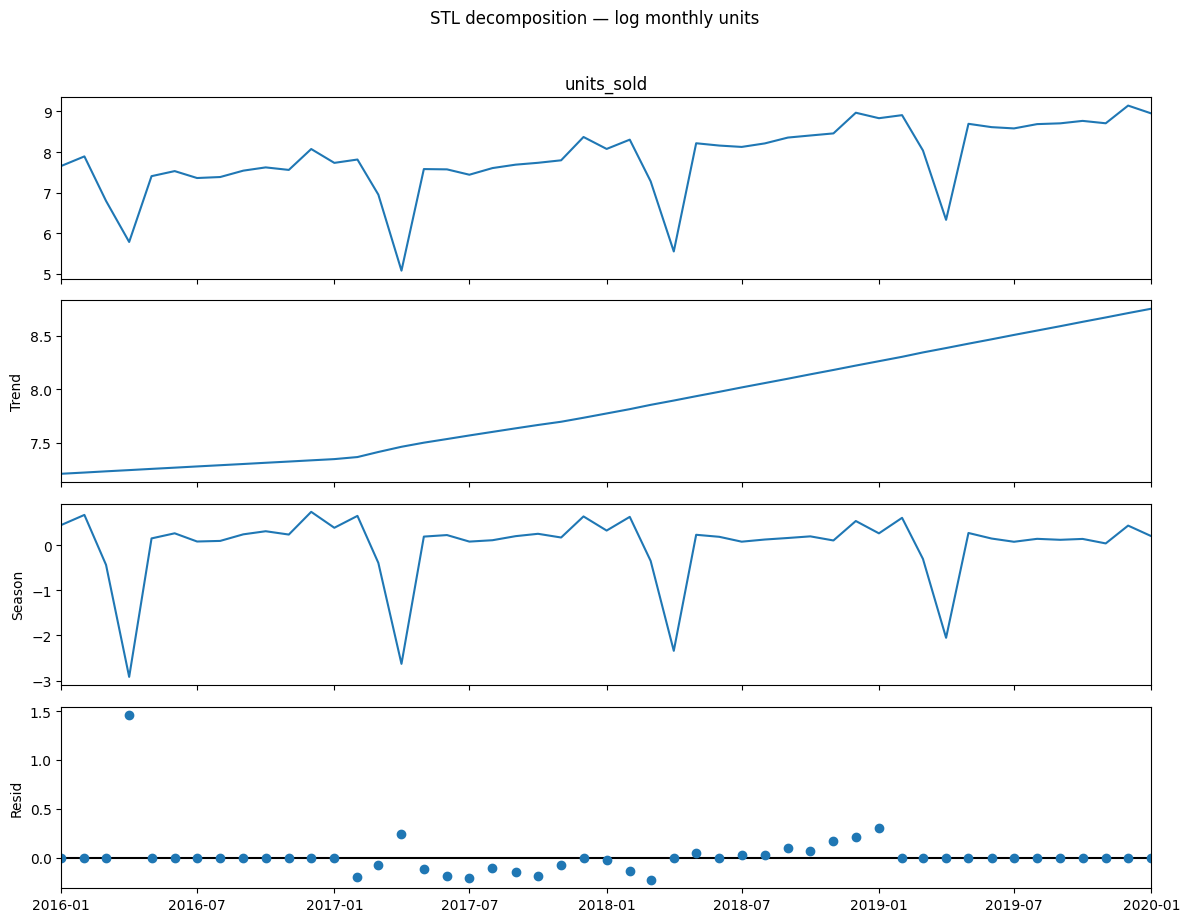

/tmp/ipykernel_589/735950707.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(


,n,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,KPSS_lags
series,,,,,,,
Log,49,1.9962,0.9987,11,0.8866,0.0100,3
Log + first difference,48,-13.3731,0.0000,10,0.4145,0.0709,38


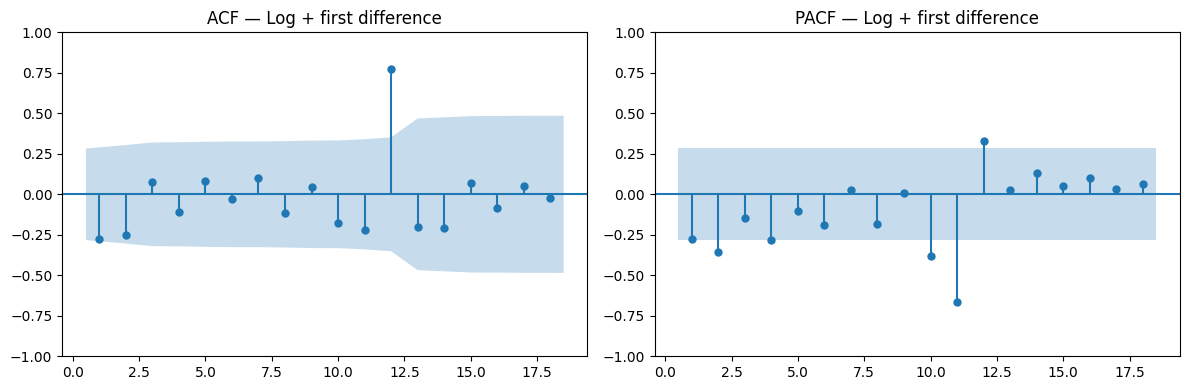

In [ ]:
assert y_train.gt(0).all(), (
    "Log yêu cầu mọi giá trị lớn hơn 0."
)

log_train = np.log(y_train)

log_stl = STL(
    log_train,
    period=12,
    robust=True
).fit()

fig = log_stl.plot()
fig.set_size_inches(12, 9)
fig.suptitle(
    "STL decomposition — log monthly units",
    y=1.02
)

plt.tight_layout()
plt.show()

log_tests = pd.DataFrame([
    stationarity_tests(log_train, "Log"),
    stationarity_tests(log_train.diff(), "Log + first difference")
]).set_index("series")

display(log_tests)

plot_correlation(
    log_train.diff(),
    "Log + first difference"
)

In [ ]:
# Chỉ sử dụng train; chưa sử dụng test để chọn mô hình
y_train = train["units_sold"].astype(float).asfreq("MS")

assert y_train.notna().all()
assert y_train.gt(0).all()

validation_horizon = 12

model_train = y_train.iloc[:-validation_horizon].copy()
validation = y_train.iloc[-validation_horizon:].copy()

assert len(model_train) >= 24
assert model_train.index.max() < validation.index.min()
assert validation.index.max() < test.index.min()

validation_split = pd.DataFrame({
    "dataset": ["Model train", "Validation", "Final test"],
    "start": [
        model_train.index.min(),
        validation.index.min(),
        test.index.min()
    ],
    "end": [
        model_train.index.max(),
        validation.index.max(),
        test.index.max()
    ],
    "months": [
        len(model_train),
        len(validation),
        len(test)
    ]
})

display(validation_split)

,dataset,start,end,months
0,Model train,2016-01-01,2019-01-01,37
1,Validation,2019-02-01,2020-01-01,12
2,Final test,2020-02-01,2021-01-01,12


In [ ]:
log_model_train = np.log(model_train)

sarima_candidates = {
    "Log SARIMA (0,1,1)(1,0,0,12)": {
        "order": (0, 1, 1),
        "seasonal_order": (1, 0, 0, 12)
    },
    "Log SARIMA (0,1,1)(0,1,1,12)": {
        "order": (0, 1, 1),
        "seasonal_order": (0, 1, 1, 12)
    }
}

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

horizon = len(validation)

validation_predictions = pd.DataFrame({
    "actual": validation
})

validation_predictions["Naive"] = model_train.iloc[-1]

previous_year = validation.index - pd.DateOffset(years=1)

assert previous_year.isin(model_train.index).all()

validation_predictions["Seasonal naive"] = (
    model_train.reindex(previous_year).to_numpy()
)

# Giữ mô hình đã fit để kiểm tra residual ở bước sau
fitted_models = {}

model_status = {
    "Naive": "OK",
    "Seasonal naive": "OK"
}

In [ ]:
hw_name = "Holt-Winters damped multiplicative"

try:
    hw_fit = ExponentialSmoothing(
        model_train,
        trend="add",
        damped_trend=True,
        seasonal="mul",
        seasonal_periods=12,
        initialization_method="estimated"
    ).fit(optimized=True)

    fitted_models[hw_name] = hw_fit

    optimizer_result = getattr(hw_fit, "mle_retvals", {})
    converged = optimizer_result.get("success", False)

    if not converged:
        model_status[hw_name] = "Chưa xác nhận hội tụ"
    else:
        forecast = hw_fit.forecast(horizon)

        assert forecast.index.equals(validation.index)
        assert np.isfinite(forecast).all()
        assert forecast.ge(0).all(), "Có dự báo âm"

        validation_predictions[hw_name] = forecast
        model_status[hw_name] = "OK"

except Exception as error:
    model_status[hw_name] = f"Lỗi: {error}"

In [ ]:
for name, config in sarima_candidates.items():
    try:
        fitted = SARIMAX(
            np.log(model_train),
            order=config["order"],
            seasonal_order=config["seasonal_order"],
            trend="n",
            enforce_stationarity=True,
            enforce_invertibility=True
        ).fit(
            disp=False,
            maxiter=500
        )

        fitted_models[name] = fitted

        if not fitted.mle_retvals.get("converged", False):
            model_status[name] = "Chưa hội tụ"
            continue

        log_forecast = fitted.get_forecast(
            steps=horizon
        ).predicted_mean

        forecast = np.exp(log_forecast)

        assert forecast.index.equals(validation.index)
        assert np.isfinite(forecast).all()
        assert forecast.gt(0).all()

        validation_predictions[name] = forecast
        model_status[name] = "OK"

    except Exception as error:
        model_status[name] = f"Lỗi: {error}"

status_table = pd.Series(
    model_status,
    name="status"
).rename_axis("model").to_frame()

display(status_table)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


,status
model,
Naive,OK
Seasonal naive,OK
Holt-Winters damped multiplicative,OK
"Log SARIMA (0,1,1)(1,0,0,12)",OK
"Log SARIMA (0,1,1)(0,1,1,12)",OK


In [ ]:
def evaluate_forecast(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    assert actual.shape == predicted.shape
    assert np.isfinite(actual).all()
    assert np.isfinite(predicted).all()

    error = predicted - actual
    denominator = np.abs(actual).sum()

    return {
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "WAPE_pct": (
            np.abs(error).sum() / denominator * 100
            if denominator > 0 else np.nan
        ),
        "Bias_units": error.mean()
    }


validation_metrics = pd.DataFrame({
    name: evaluate_forecast(
        validation_predictions["actual"],
        validation_predictions[name]
    )
    for name in validation_predictions.columns
    if name != "actual"
}).T

validation_metrics.index.name = "model"

validation_metrics = validation_metrics.sort_values("MAE")

seasonal_naive_mae = validation_metrics.loc[
    "Seasonal naive", "MAE"
]

validation_metrics["MAE_improvement_vs_seasonal_naive_pct"] = (
    (1 - validation_metrics["MAE"] / seasonal_naive_mae) * 100
    if seasonal_naive_mae > 0 else np.nan
)

display(validation_metrics.round(2))

,MAE,RMSE,WAPE_pct,Bias_units,MAE_improvement_vs_seasonal_naive_pct
model,,,,,
Holt-Winters damped multiplicative,626.5200,704.6200,10.8500,-171.1400,64.4800
Naive,"1,722.3300","2,383.3000",29.8300,"1,075.3300",2.3400
Seasonal naive,"1,763.6700","1,907.0600",30.5400,"-1,763.6700",0.0000
"Log SARIMA (0,1,1)(1,0,0,12)","2,027.4500","2,677.7000",35.1100,"2,001.6000",-14.9600
"Log SARIMA (0,1,1)(0,1,1,12)","2,379.4100","3,118.6200",41.2000,"2,335.0300",-34.9100


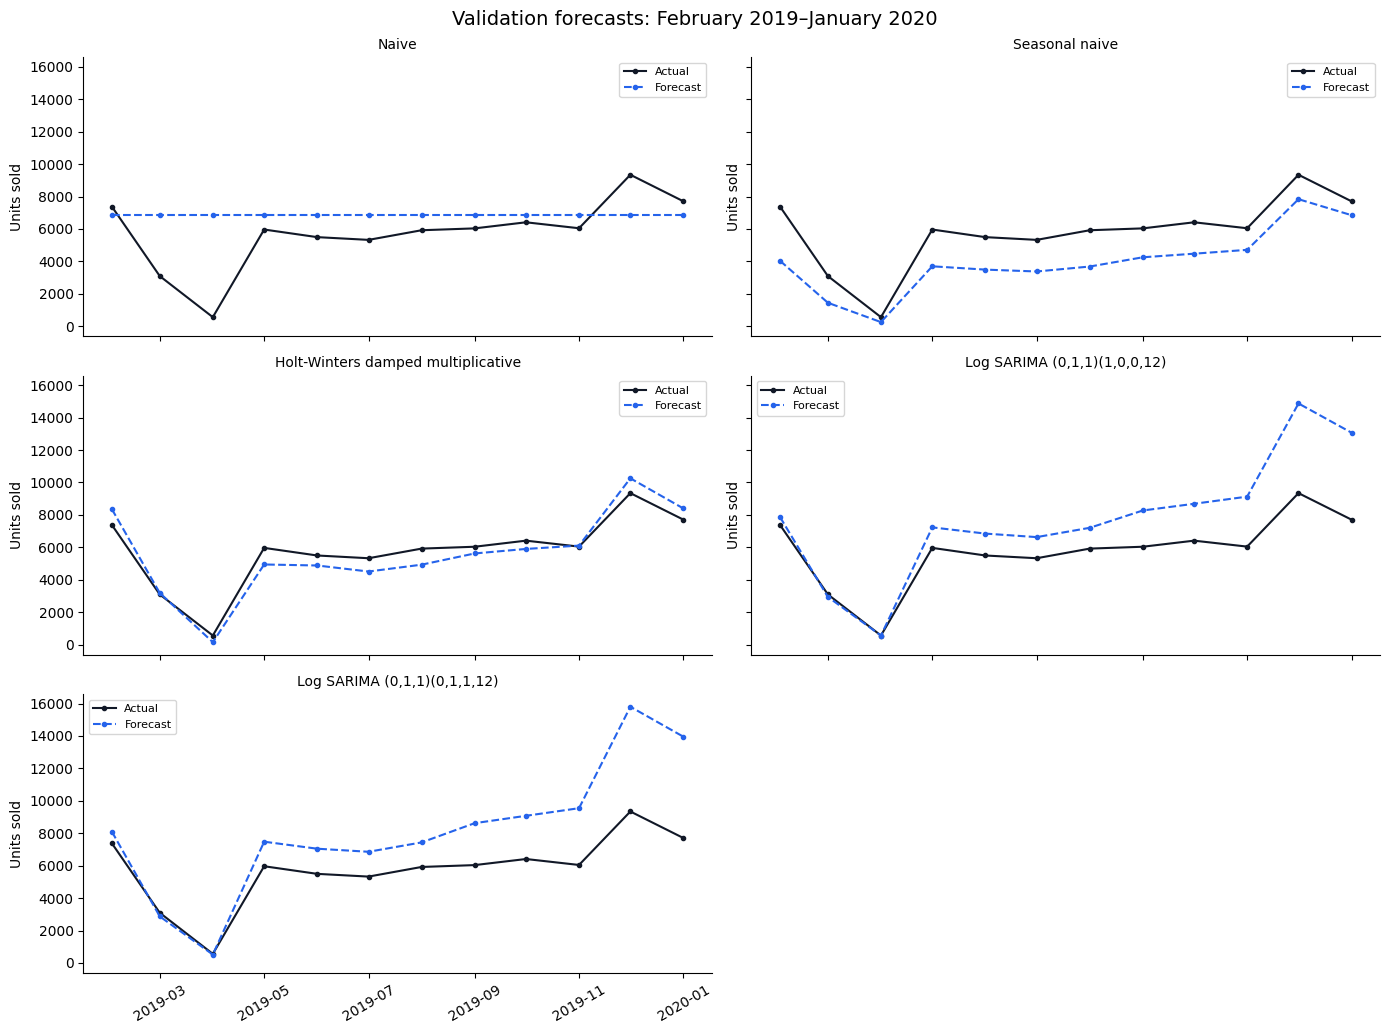

In [ ]:
models_to_plot = [
    column
    for column in validation_predictions.columns
    if column != "actual"
]

ncols = 2
nrows = (len(models_to_plot) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 3.5 * nrows),
    sharex=True,
    sharey=True,
    squeeze=False
)

for ax, name in zip(axes.flat, models_to_plot):
    ax.plot(
        validation.index,
        validation,
        label="Actual",
        color="#111827",
        marker="o",
        markersize=3
    )

    ax.plot(
        validation.index,
        validation_predictions[name],
        label="Forecast",
        color="#2563EB",
        linestyle="--",
        marker="o",
        markersize=3
    )

    ax.set_title(name, fontsize=10)
    ax.set_ylabel("Units sold")
    ax.tick_params(axis="x", rotation=30)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8)

for ax in list(axes.flat)[len(models_to_plot):]:
    ax.set_visible(False)

fig.suptitle(
    "Validation forecasts: February 2019–January 2020",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
selected_model_name = "Holt-Winters damped multiplicative"

assert model_status[selected_model_name] == "OK"

selected_fit = fitted_models[selected_model_name]

residual_table = pd.DataFrame({
    "actual": model_train,
    "fitted": selected_fit.fittedvalues
})

residual_table["residual"] = (
    residual_table["actual"] - residual_table["fitted"]
)

# Chỉ số bổ sung để xem sai số so với mức dự báo
residual_table["relative_residual_pct"] = (
    residual_table["residual"]
    / residual_table["fitted"].replace(0, np.nan)
    * 100
)

display(residual_table.head())

display(
    residual_table[
        ["residual", "relative_residual_pct"]
    ].describe().round(2)
)

,actual,fitted,residual,relative_residual_pct
month,,,,
2016-01-01,"2,116.0000","2,393.7209",-277.7209,-11.6021
2016-02-01,"2,676.0000","2,290.1910",385.8090,16.8462
2016-03-01,895.0000,671.3392,223.6608,33.3156
2016-04-01,326.0000,24.0044,301.9956,"1,258.0859"
2016-05-01,"1,646.0000","2,136.2898",-490.2898,-22.9505


,residual,relative_residual_pct
count,37.0000,37.0000
mean,32.9700,49.3200
std,187.3700,213.0800
min,-490.2900,-22.9500
25%,-61.8000,-2.8300
50%,31.3300,0.7400
75%,155.7000,7.7900
max,394.3600,"1,258.0900"


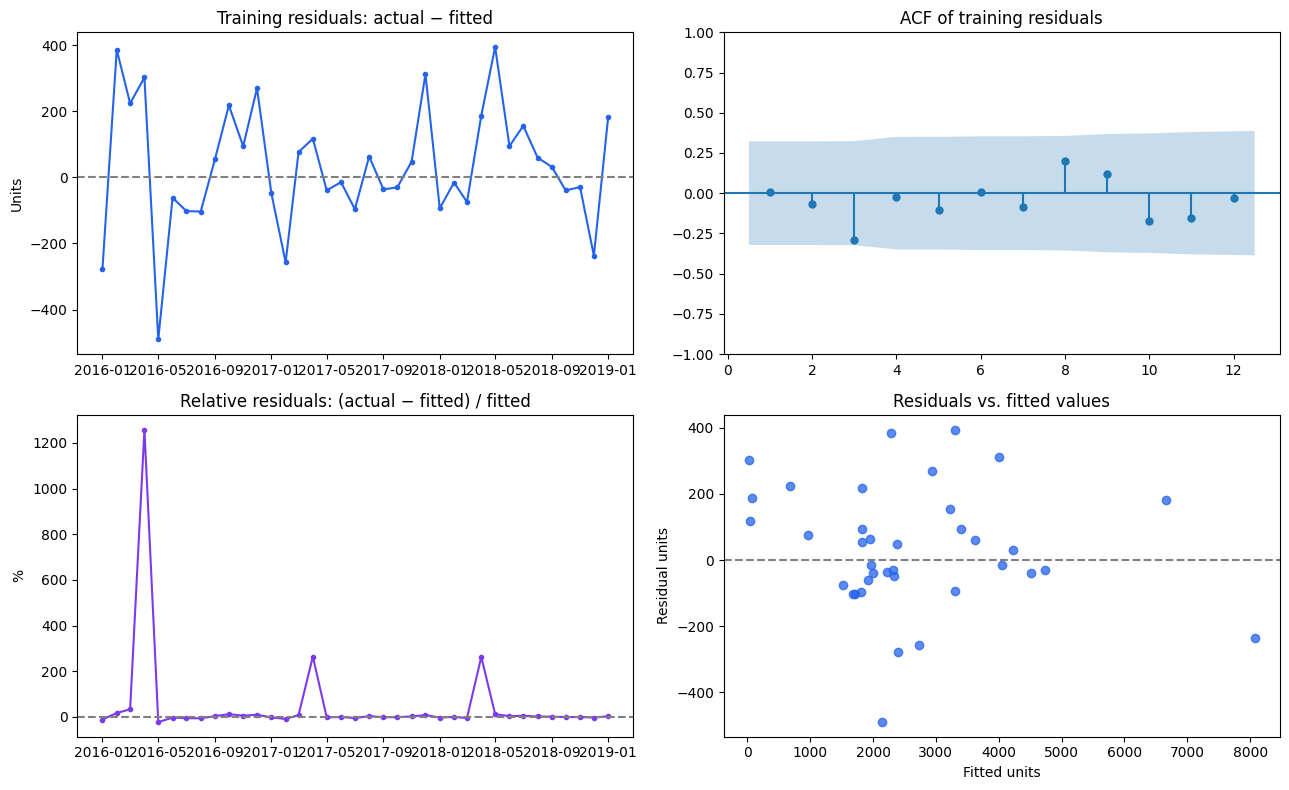

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

residuals = residual_table["residual"].dropna()
relative_residuals = (
    residual_table["relative_residual_pct"].dropna()
)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].plot(
    residuals.index,
    residuals,
    color="#2563EB",
    marker="o",
    markersize=3
)

axes[0, 0].axhline(0, color="gray", linestyle="--")
axes[0, 0].set_title("Training residuals: actual − fitted")
axes[0, 0].set_ylabel("Units")

plot_acf(
    residuals,
    lags=12,
    zero=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title("ACF of training residuals")

axes[1, 0].plot(
    relative_residuals.index,
    relative_residuals,
    color="#7C3AED",
    marker="o",
    markersize=3
)

axes[1, 0].axhline(0, color="gray", linestyle="--")
axes[1, 0].set_title("Relative residuals: (actual − fitted) / fitted")
axes[1, 0].set_ylabel("%")

axes[1, 1].scatter(
    residual_table["fitted"],
    residual_table["residual"],
    color="#2563EB",
    alpha=0.75
)

axes[1, 1].axhline(0, color="gray", linestyle="--")
axes[1, 1].set_title("Residuals vs. fitted values")
axes[1, 1].set_xlabel("Fitted units")
axes[1, 1].set_ylabel("Residual units")

plt.tight_layout()
plt.show()

In [ ]:
validation_errors = pd.DataFrame({
    "actual": validation,
    "forecast": validation_predictions[selected_model_name]
})

# Cùng quy ước với Bias trong bảng đánh giá
validation_errors["forecast_error"] = (
    validation_errors["forecast"]
    - validation_errors["actual"]
)

validation_errors["absolute_error"] = (
    validation_errors["forecast_error"].abs()
)

display(
    validation_errors
    .sort_values("absolute_error", ascending=False)
    .round(2)
)

,actual,forecast,forecast_error,absolute_error
month,,,,
2019-05-01,"5,966.0000","4,942.9000","-1,023.1000","1,023.1000"
2019-08-01,"5,922.0000","4,930.4700",-991.5300,991.5300
2019-02-01,"7,383.0000","8,357.8100",974.8100,974.8100
2019-12-01,"9,343.0000","10,256.9900",913.9900,913.9900
2019-07-01,"5,328.0000","4,508.5100",-819.4900,819.4900
2020-01-01,"7,706.0000","8,397.4100",691.4100,691.4100
2019-06-01,"5,497.0000","4,880.5200",-616.4800,616.4800
2019-10-01,"6,412.0000","5,901.5000",-510.5000,510.5000
2019-09-01,"6,037.0000","5,622.2700",-414.7300,414.7300


In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

final_train = train["units_sold"].astype(float).asfreq("MS")
final_actual = test["units_sold"].astype(float).asfreq("MS")

assert final_train.notna().all()
assert final_actual.notna().all()
assert final_train.gt(0).all()
assert final_train.index.max() < final_actual.index.min()

final_hw_fit = ExponentialSmoothing(
    final_train,
    trend="add",
    damped_trend=True,
    seasonal="mul",
    seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)

optimizer_result = getattr(final_hw_fit, "mle_retvals", {})

assert optimizer_result.get("success", False), (
    "Mô hình chưa xác nhận hội tụ. Kiểm tra cảnh báo trước khi tiếp tục."
)

print(
    "Đã fit trên:",
    final_train.index.min().strftime("%Y-%m"),
    "đến",
    final_train.index.max().strftime("%Y-%m")
)

Đã fit trên: 2016-01 đến 2020-01


In [ ]:
test_horizon = len(final_actual)

hw_test_forecast = final_hw_fit.forecast(test_horizon)

assert hw_test_forecast.index.equals(final_actual.index)
assert np.isfinite(hw_test_forecast).all()
assert hw_test_forecast.ge(0).all()

final_predictions = pd.DataFrame({
    "actual": final_actual,
    "Holt-Winters": hw_test_forecast
})

final_predictions["Naive"] = final_train.iloc[-1]

previous_year_months = (
    final_actual.index - pd.DateOffset(years=1)
)

assert previous_year_months.isin(final_train.index).all()

final_predictions["Seasonal naive"] = (
    final_train
    .reindex(previous_year_months)
    .to_numpy()
)

display(final_predictions.round(2))

,actual,Holt-Winters,Naive,Seasonal naive
2020-02-01,"8,385.0000","8,329.4700","7,706.0000","7,383.0000"
2020-03-01,"2,392.0000","3,174.3500","7,706.0000","3,095.0000"
2020-04-01,694.0000,675.7800,"7,706.0000",562.0000
2020-05-01,"3,256.0000","6,374.0300","7,706.0000","5,966.0000"
2020-06-01,"2,738.0000","5,910.5200","7,706.0000","5,497.0000"
2020-07-01,"1,941.0000","5,521.9400","7,706.0000","5,328.0000"
2020-08-01,"1,526.0000","5,974.0500","7,706.0000","5,922.0000"
2020-09-01,"1,328.0000","6,213.6300","7,706.0000","6,037.0000"
2020-10-01,"1,042.0000","6,434.3000","7,706.0000","6,412.0000"
2020-11-01,"1,044.0000","6,164.7000","7,706.0000","6,045.0000"


In [ ]:
final_metrics = pd.DataFrame({
    name: evaluate_forecast(
        final_predictions["actual"],
        final_predictions[name]
    )
    for name in ["Holt-Winters", "Naive", "Seasonal naive"]
}).T

final_metrics.index.name = "model"

baseline_mae = final_metrics.loc["Seasonal naive", "MAE"]

final_metrics["MAE_improvement_vs_seasonal_naive_pct"] = (
    (1 - final_metrics["MAE"] / baseline_mae) * 100
    if baseline_mae > 0 else np.nan
)

display(final_metrics.round(2))

,MAE,RMSE,WAPE_pct,Bias_units,MAE_improvement_vs_seasonal_naive_pct
model,,,,,
Holt-Winters,"3,652.6300","4,291.2300",153.2300,"3,640.3400",-2.0300
Naive,"5,435.4200","5,668.6400",228.0200,"5,322.2500",-51.8300
Seasonal naive,"3,579.9200","4,139.8300",150.1800,"3,390.9200",0.0000


In [ ]:
metrics_to_compare = [
    "MAE",
    "RMSE",
    "WAPE_pct",
    "Bias_units"
]

hw_comparison = pd.DataFrame({
    "Validation": validation_metrics.loc[
        "Holt-Winters damped multiplicative",
        metrics_to_compare
    ],
    "Final test": final_metrics.loc[
        "Holt-Winters",
        metrics_to_compare
    ]
}).T

display(hw_comparison.round(2))

,MAE,RMSE,WAPE_pct,Bias_units
Validation,626.5200,704.6200,10.8500,-171.1400
Final test,"3,652.6300","4,291.2300",153.2300,"3,640.3400"


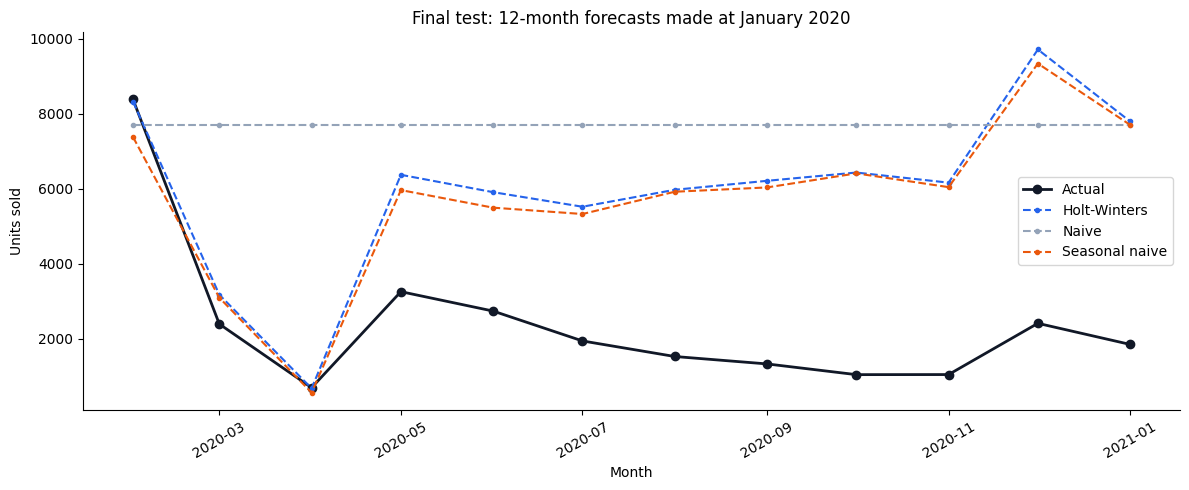

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    final_predictions.index,
    final_predictions["actual"],
    label="Actual",
    color="#111827",
    marker="o",
    linewidth=2
)

styles = {
    "Holt-Winters": "#2563EB",
    "Naive": "#94A3B8",
    "Seasonal naive": "#EA580C"
}

for name, color in styles.items():
    ax.plot(
        final_predictions.index,
        final_predictions[name],
        label=name,
        color=color,
        linestyle="--",
        marker="o",
        markersize=3
    )

ax.set_title(
    "Final test: 12-month forecasts made at January 2020"
)
ax.set_xlabel("Month")
ax.set_ylabel("Units sold")
ax.tick_params(axis="x", rotation=30)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

plt.tight_layout()
plt.show()

### Final forecast evaluation

Holt-Winters with a damped additive trend and multiplicative seasonality was selected using validation MAE. It achieved a validation MAE of 626.52 units and WAPE of 10.85%, reducing MAE by 64.48% relative to seasonal naive.

Performance deteriorated substantially on the final test period, February 2020–January 2021. Test MAE increased to 3,652.63 units and WAPE reached 153.23%. Mean forecast error was +3,640.34 units, indicating substantial overforecasting.

Seasonal naive achieved the lowest test MAE among the three evaluated methods, at 3,579.92 units. Holt-Winters was 2.03% worse by MAE. However, seasonal naive also had a high WAPE of 150.18%, so none of the evaluated methods provided satisfactory forecasts for this period.

The forecasts retained historical seasonal patterns, while observed sales remained substantially below the predicted levels from May 2020 onward. This suggests a change in the sales process relative to the training period, but the analysis does not establish its cause.

These results highlight the limitations of a fixed 12-month forecast under changing conditions. The selected model should not be treated as reliable for operational planning based on its validation performance alone. Further work should verify data completeness and investigate changes by channel, store, and product category.

1. Chạy dự báo từng tháng
Ví dụ:
- Dùng dữ liệu đến 01/2020 → dự báo 02/2020.
- Khi biết actual 02/2020, bổ sung vào lịch sử → dự báo 03/2020.
- Tiếp tục đến 01/2021.
Code chỉ bổ sung actual sau khi tạo dự báo cho tháng đó, tránh dùng dữ liệu tương lai.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import ExponentialSmoothing

history = train["units_sold"].astype(float).asfreq("MS").copy()
rolling_actual = test["units_sold"].astype(float).asfreq("MS")

assert history.notna().all()
assert rolling_actual.notna().all()
assert history.gt(0).all()
assert history.index.max() < rolling_actual.index.min()

rolling_rows = []

for forecast_month, actual_value in rolling_actual.items():
    # Lịch sử phải kết thúc đúng một tháng trước tháng dự báo
    assert (
        history.index.max() + pd.offsets.MonthBegin(1)
        == forecast_month
    )

    rolling_fit = ExponentialSmoothing(
        history,
        trend="add",
        damped_trend=True,
        seasonal="mul",
        seasonal_periods=12,
        initialization_method="estimated"
    ).fit(optimized=True)

    optimizer_result = getattr(rolling_fit, "mle_retvals", {})

    assert optimizer_result.get("success", False), (
        f"Mô hình chưa hội tụ khi dự báo {forecast_month:%Y-%m}. "
        "Dừng để kiểm tra, không bỏ qua tháng này."
    )

    hw_forecast = float(rolling_fit.forecast(1).iloc[0])

    assert np.isfinite(hw_forecast)
    assert hw_forecast >= 0

    # Baseline cũng chỉ sử dụng thông tin đã có
    naive_forecast = float(history.iloc[-1])

    previous_year_month = (
        forecast_month - pd.DateOffset(years=1)
    )

    assert previous_year_month in history.index

    seasonal_naive_forecast = float(
        history.loc[previous_year_month]
    )

    rolling_rows.append({
        "month": forecast_month,
        "actual": float(actual_value),
        "Holt-Winters": hw_forecast,
        "Naive": naive_forecast,
        "Seasonal naive": seasonal_naive_forecast,
        "history_months": len(history)
    })

    # Chỉ cập nhật actual sau khi đã tạo tất cả dự báo
    new_observation = pd.Series(
        [float(actual_value)],
        index=pd.DatetimeIndex([forecast_month]),
        name=history.name
    )

    history = pd.concat(
        [history, new_observation]
    ).asfreq("MS")

rolling_predictions = (
    pd.DataFrame(rolling_rows)
    .set_index("month")
)

assert rolling_predictions.index.equals(rolling_actual.index)
assert rolling_predictions.notna().all().all()

display(rolling_predictions.round(2))

,actual,Holt-Winters,Naive,Seasonal naive,history_months
month,,,,,
2020-02-01,"8,385.0000","8,329.4700","7,706.0000","7,383.0000",49
2020-03-01,"2,392.0000","3,186.1500","8,385.0000","3,095.0000",50
2020-04-01,694.0000,653.0000,"2,392.0000",562.0000,51
2020-05-01,"3,256.0000","5,778.2800",694.0000,"5,966.0000",52
2020-06-01,"2,738.0000","3,727.2400","3,256.0000","5,497.0000",53
2020-07-01,"1,941.0000","2,296.9800","2,738.0000","5,328.0000",54
2020-08-01,"1,526.0000","1,458.9800","1,941.0000","5,922.0000",55
2020-09-01,"1,328.0000",749.0100,"1,526.0000","6,037.0000",56
2020-10-01,"1,042.0000",345.9900,"1,328.0000","6,412.0000",57


In [ ]:
rolling_metrics = pd.DataFrame({
    model: evaluate_forecast(
        rolling_predictions["actual"],
        rolling_predictions[model]
    )
    for model in ["Holt-Winters", "Naive", "Seasonal naive"]
}).T

rolling_metrics.index.name = "model"

rolling_baseline_mae = rolling_metrics.loc[
    "Seasonal naive", "MAE"
]

rolling_metrics["MAE_improvement_vs_seasonal_naive_pct"] = (
    (1 - rolling_metrics["MAE"] / rolling_baseline_mae) * 100
    if rolling_baseline_mae > 0 else np.nan
)

display(rolling_metrics.sort_values("MAE").round(2))

,MAE,RMSE,WAPE_pct,Bias_units,MAE_improvement_vs_seasonal_naive_pct
model,,,,,
Holt-Winters,758.7200,"1,042.6700",31.8300,18.2200,78.8100
Naive,"1,256.5000","2,024.9800",52.7100,488.1700,64.9000
Seasonal naive,"3,579.9200","4,139.8300",150.1800,"3,390.9200",0.0000


In [ ]:
comparison_metrics = [
    "MAE",
    "RMSE",
    "WAPE_pct",
    "Bias_units"
]

forecast_strategy_comparison = pd.DataFrame({
    "Fixed origin — horizons 1 to 12": final_metrics.loc[
        "Holt-Winters",
        comparison_metrics
    ],
    "Monthly update — horizon 1": rolling_metrics.loc[
        "Holt-Winters",
        comparison_metrics
    ]
}).T

display(forecast_strategy_comparison.round(2))

fixed_mae = final_metrics.loc["Holt-Winters", "MAE"]
rolling_mae = rolling_metrics.loc["Holt-Winters", "MAE"]

if fixed_mae > 0:
    improvement = (1 - rolling_mae / fixed_mae) * 100

    print(
        "Thay đổi MAE so với dự báo 12 tháng cùng lúc:",
        f"{improvement:.2f}% cải thiện"
    )

,MAE,RMSE,WAPE_pct,Bias_units
Fixed origin — horizons 1 to 12,"3,652.6300","4,291.2300",153.2300,"3,640.3400"
Monthly update — horizon 1,758.7200,"1,042.6700",31.8300,18.2200


Thay đổi MAE so với dự báo 12 tháng cùng lúc: 79.23% cải thiện


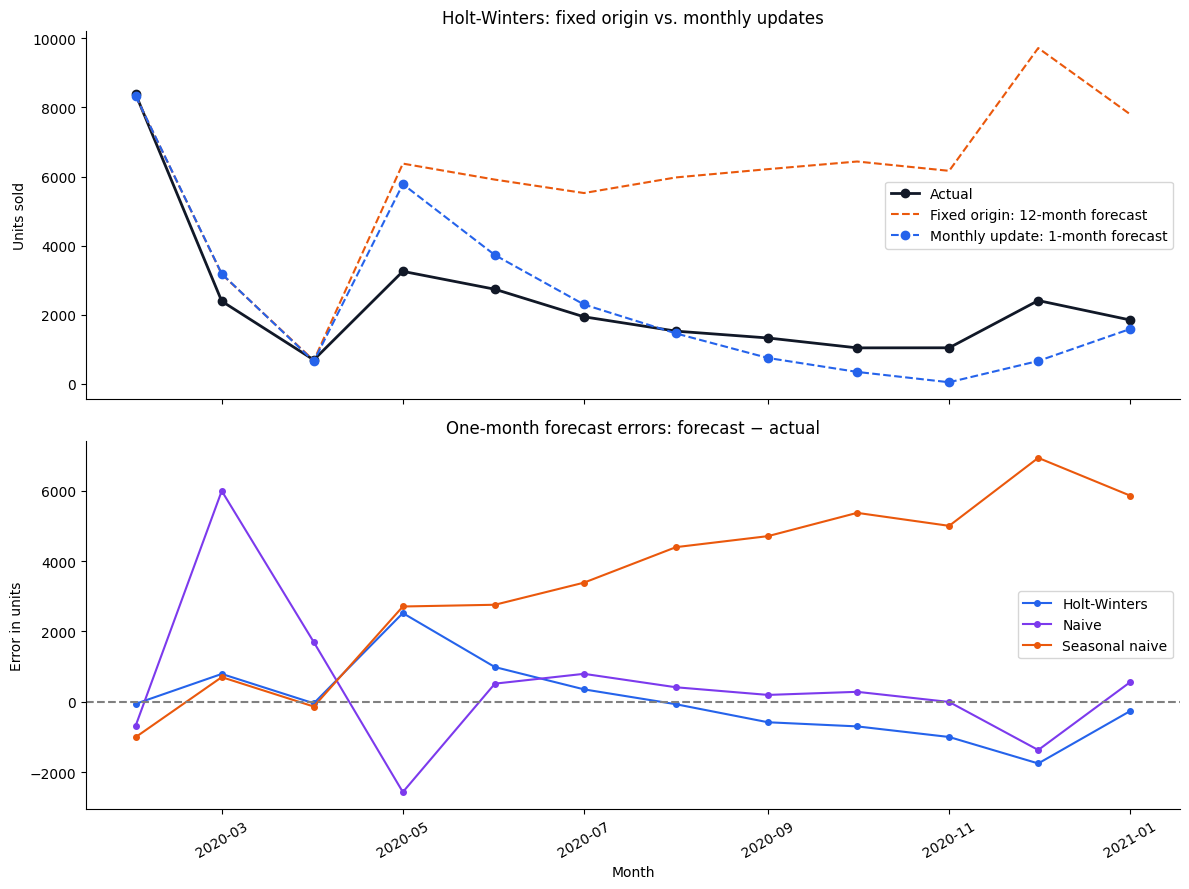

In [ ]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    sharex=True
)

axes[0].plot(
    rolling_predictions.index,
    rolling_predictions["actual"],
    color="#111827",
    marker="o",
    linewidth=2,
    label="Actual"
)

axes[0].plot(
    final_predictions.index,
    final_predictions["Holt-Winters"],
    color="#EA580C",
    linestyle="--",
    label="Fixed origin: 12-month forecast"
)

axes[0].plot(
    rolling_predictions.index,
    rolling_predictions["Holt-Winters"],
    color="#2563EB",
    marker="o",
    linestyle="--",
    label="Monthly update: 1-month forecast"
)

axes[0].set_title("Holt-Winters: fixed origin vs. monthly updates")
axes[0].set_ylabel("Units sold")
axes[0].legend()

for model, color in {
    "Holt-Winters": "#2563EB",
    "Naive": "#7C3AED",
    "Seasonal naive": "#EA580C"
}.items():
    errors = (
        rolling_predictions[model]
        - rolling_predictions["actual"]
    )

    axes[1].plot(
        rolling_predictions.index,
        errors,
        label=model,
        color=color,
        marker="o",
        markersize=4
    )

axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_title("One-month forecast errors: forecast − actual")
axes[1].set_ylabel("Error in units")
axes[1].set_xlabel("Month")
axes[1].legend()

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Supplementary experiment: monthly forecast updates

An expanding-window evaluation was conducted over February 2020–January 2021. The Holt-Winters configuration was kept unchanged, but its parameters were re-estimated each month using only observations available before the forecast date.

For one-month-ahead forecasts, Holt-Winters achieved an MAE of 758.72 units and WAPE of 31.83%. It outperformed seasonal naive by 78.81% and naive by approximately 39.62% in MAE.

Compared with the fixed-origin 12-month forecast, monthly updating reduced MAE by 79.23%. This improvement reflects both a shorter forecast horizon and access to newly observed sales, rather than a change in model specification.

Mean forecast error was close to zero at +18.22 units. However, overforecasting in some earlier months offset underforecasting in later months. Low aggregate bias therefore did not imply consistently small monthly errors.

The results support further evaluation of monthly updates for short-term sales planning. They do not establish reliable performance for annual planning, individual products, or inventory decisions.

This was a supplementary analysis designed after reviewing the original test results. Its findings should be confirmed on additional periods or through prospective monitoring. The original fixed-origin test results remain part of the reported evaluation.

# Conclusions and Business Implications

## 1. Data Preparation and Validation

The analytical dataset contains 62,884 sales line items across 26,326 orders and 11,887 customers.

No duplicate order-line keys were detected. Missing delivery information for physical-store transactions and missing store area for online transactions were retained rather than removed indiscriminately.

All seven reconciliation metrics matched between SQL and the CSV-based calculations: row count, distinct orders, distinct customers, units sold, revenue, total cost, and gross profit. Counts matched exactly, while monetary differences were within the specified tolerance of USD 0.01.

February 2021 was excluded from monthly forecasting because the dataset ends on 20 February 2021.

## 2. Customer Analysis

Champions represent 14.97% of customers and contribute 33.64% of historical revenue. At Risk customers represent 13.65% of customers and account for 22.16% of historical revenue.

The median observed interval between consecutive orders is 259 days. Purchase intervals vary considerably, so a short, universal inactivity threshold requires further justification.

Among the 654 At Risk customers eligible for personal-cycle comparisons, the median recency-to-cycle ratio is 3.25. This result covers 40.32% of the segment and should not be generalized to all At Risk customers.

RFM labels describe relative historical purchasing behavior. They do not establish customer loyalty or confirm churn.

## 3. Forecasting Results

Holt-Winters with a damped additive trend and multiplicative seasonality performed best among the evaluated candidates on validation, achieving an MAE of 626.52 units and WAPE of 10.85%.

Performance deteriorated on the final test period, February 2020–January 2021. The fixed-origin 12-month forecast produced an MAE of 3,652.63 units and WAPE of 153.23%. Seasonal naive performed slightly better, although its errors were also substantial.

A supplementary monthly-update experiment achieved an MAE of 758.72 units and WAPE of 31.83%. This represents a 79.23% reduction in MAE compared with the fixed-origin forecast and reflects both a shorter forecast horizon and access to newly observed sales.

Monthly-update Holt-Winters also outperformed the one-month-ahead naive baseline by approximately 39.62% in MAE.

Its mean forecast error was close to zero, but positive and negative monthly errors offset each other. Low aggregate bias therefore did not imply consistently small errors.

## 4. Proposed Business Actions

- Review high-value customers with prolonged inactivity, combining RFM scores with individual purchase histories.
- Test targeted reactivation campaigns against a control group before assuming commercial benefit.
- Further evaluate monthly forecast updates for short-term sales planning.
- Investigate sales changes by channel, store, and product category before attributing the decline to a particular cause.
- Monitor MAE, WAPE, bias, and individual monthly errors together.

## 5. Limitations

- RFM uses the full observed history, giving longer-tenure customers more time to accumulate orders and spending.
- Purchase-interval analysis includes completed repeat purchases and does not fully represent customers who have not returned.
- Forecasting uses a short monthly series and a limited evaluation period.
- The monthly-update experiment was designed after reviewing the original test results. Its findings require confirmation on additional periods or through prospective monitoring.
- The observed sales decline suggests changing conditions, but this analysis does not establish its cause.
- Aggregated units sold are not a direct measure of unconstrained demand and do not support SKU-level inventory decisions on their own.

In [56]:
# Lấy kết quả dự báo cập nhật hằng tháng
forecast_export = rolling_predictions[
    ["actual", "Holt-Winters", "Naive", "Seasonal naive"]
].copy()

forecast_export = forecast_export.rename(columns={
    "actual": "ActualUnits",
    "Holt-Winters": "RollingHW",
    "Naive": "RollingNaive",
    "Seasonal naive": "SeasonalNaive"
})

# Thêm dự báo 12 tháng được tạo một lần
forecast_export["FixedHW"] = final_predictions["Holt-Winters"]
forecast_export["FixedNaive"] = final_predictions["Naive"]

# Đưa tháng từ index thành một cột
forecast_export.index.name = "Month"
forecast_export = forecast_export.reset_index()

# Kiểm tra trước khi xuất
assert len(forecast_export) == 12, "Kiểm tra lại số tháng dự báo."
assert not forecast_export.isna().any().any(), "Có dữ liệu bị thiếu."

display(forecast_export)

# Xuất và tải file xuống
forecast_export.to_csv(
    "ForecastMonthly.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

from google.colab import files
files.download("ForecastMonthly.csv")

,Month,ActualUnits,RollingHW,RollingNaive,SeasonalNaive,FixedHW,FixedNaive
0,2020-02-01,"8,385.0000","8,329.4694","7,706.0000","7,383.0000","8,329.4694","7,706.0000"
1,2020-03-01,"2,392.0000","3,186.1517","8,385.0000","3,095.0000","3,174.3501","7,706.0000"
2,2020-04-01,694.0000,652.9976,"2,392.0000",562.0000,675.7774,"7,706.0000"
3,2020-05-01,"3,256.0000","5,778.2776",694.0000,"5,966.0000","6,374.0330","7,706.0000"
4,2020-06-01,"2,738.0000","3,727.2402","3,256.0000","5,497.0000","5,910.5209","7,706.0000"
5,2020-07-01,"1,941.0000","2,296.9830","2,738.0000","5,328.0000","5,521.9370","7,706.0000"
6,2020-08-01,"1,526.0000","1,458.9813","1,941.0000","5,922.0000","5,974.0472","7,706.0000"
7,2020-09-01,"1,328.0000",749.0056,"1,526.0000","6,037.0000","6,213.6316","7,706.0000"
8,2020-10-01,"1,042.0000",345.9888,"1,328.0000","6,412.0000","6,434.3040","7,706.0000"
9,2020-11-01,"1,044.0000",46.8276,"1,042.0000","6,045.0000","6,164.7016","7,706.0000"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>